# Workflows to Skills: Teaching an Agent a Procedure Without Touching Its Weights

Every team has an agent that did something right on Tuesday and can't tell you
how on Wednesday.

The run happened. The tools were called in the right order, the payee was
screened, the money went where it should. 

Then the context window closed, and
the next request started from zero — the same model, working the same
procedure out from scratch, and this time guessing.

This is the problem we are trying to solve, at first seems harmless because you have some agent memory management in place, but agent memory is only the first lever in building truly efficient and capable AI Agents. Guessing right with high success rate is impressive, but we are still going through the guessing process.

**This notebook is about not guessing twice.**

We take one procedure at one insurer, watch an agent get it wrong for want of
knowing, teach it once, and then let its **own successful runs** become a
reviewed, monitored, *removable* instruction. No fine-tuning. No one editing
the system prompt.

It is the first of five notebooks in
[`examples/continual_learning`](.), and all five are set at the same company:
**Calderwood Insurance**, a fictional UK insurer. Everything about Calderwood
is invented — its systems, its codes, its payment limits — so the model can't
know any of it before it is told. That is the point of using it.

Each notebook runs top to bottom on a laptop with nothing but an OpenAI key.

## Key takeaways

- ***A run is evidence. A skill is an instruction.*** *Workflow memory records what happened once; a skill says what to do next time. Promotion is the gate between the two.*
- ***The tools don't know your house rules.*** *A payments system will release anything it's asked to. The order, the checks and the things you never do live in people's heads — until memory holds them.*
- ***Frequency alone never promotes.*** *A procedure has to repeat, succeed by your definition of success, and show up under different wordings before it is worth distilling.*
- ***A branch is a different procedure.*** *Paying a claim, freezing a payment and referring it up are three paths. Each has to earn its own skill.*
- ***A skill points at a value; it doesn't copy it.*** *The payout limit lives in entity memory. When the limit changes, the skill doesn't have to.*
- ***Shadow first, authority second.*** *A distilled skill is a model's generalisation of your logs. It earns a place in the prompt through review, not through confidence.*
- ***A skill that can't be demoted is a liability.*** *The world changes; the monitor notices, the skill steps down, and the raw evidence comes back.*

## How this notebook is organised

Seven parts. Each one opens by saying what you'll learn in it and what you'll
have at the end of it.

| Part | What happens | What you have at the end |
|---|---|---|
| **1 · The use case** | One payment at Calderwood, and the idea of learning in token space | The problem, and the vocabulary for the fix |
| **2 · Setup and the world** | A memory store, Calderwood's claims, ten tools and a grader | A desk you can run requests against |
| **3 · The baseline** | Ada with the tools and no knowledge of the desk | A measured picture of what goes wrong |
| **4 · Learning** | Coached runs become trajectory classes, one class becomes a reviewed skill | An active `SKILL.md`, and the reason it carries weight |
| **5 · Measuring it** | The skill against no learning, against a longer prompt, and against its own raw evidence | Numbers, and their limits |
| **6 · When the world changes** | A payout limit moves, then a payment rule does | A skill that survived one change and was retired by the other |
| **7 · In the UI, and wrap-up** | The same run in the MemoRizz local UI; what the numbers don't show; FAQ | Somewhere to look, and what to distrust |

### ⭐ The webinar path

Sections marked with a ⭐ are the ones to show in a live walkthrough. Taken
in order they tell the whole story in eleven stops; everything between them
is supporting detail you can skip on screen and leave for people to read
afterwards.

| Stop | Section | What to show |
|---|---|---|
| 1 | The use case: a £1,840 payment, on a Tuesday in September | The problem in one scene: a correct-looking run that isn't what the desk requires |
| 2 | The loop we are going to build | The whole lifecycle on one diagram, before any code |
| 3 | Ten tools that say little and enforce less | The map of the three tool paths: PAY, HOLD and STOP |
| 4 | 2 · The scene, for real: Ada with no memory of the desk | The baseline, live: what Ada does with tools and no procedure |
| 5 | From runs to trajectory classes | How repeated runs become evidence: shapes, not values |
| 6 | 5 · Promotion: distil, validate, and wait in shadow | The skill is written, checked in code, and held for a person |
| 7 | Shadow means stored, not trusted | What the skill kept and what it dropped, line by line |
| 8 | 7 · The comparison: no learning, a longer prompt, or a learned skill | The scoreboard: three versions of Ada on requests nobody coached |
| 9 | 9 · January 2027: a limit changes, and the skill doesn't have to | A rule changes and the skill keeps working, because it never stored the number |
| 10 | 10 · The same month: Tally starts holding large payments, and the skill steps down | A rule changes and the skill is demoted on its own |
| 11 | See it in the MemoRizz UI | The same run in the UI: workflows, the skill, the session |

# Part 1 · The use case

This part is the *why*. You'll meet one request at one insurer, see why a
capable model with the right tools still can't be trusted with it, and get the
four terms the rest of the notebook is built from. No code runs here. By the
end you'll know what "learning" will have to mean before we build any of it.

## ⭐ The use case: a £1,840 payment, on a Tuesday in September

**Calderwood Insurance**, the home claims desk, September 2026.

**Tom Okafor** is a Grade 1 claims handler.

**Ada** is Calderwood's internal claims support assistant: a language model
with ten tools into the claims systems:

1. **Beacon** (claims), 
2. **the Ringfence** (sanctions screening)
3. and **Tally** (payments).

Tom has agreed £1,840 with a joinery firm for a storm-damaged door. The firm
has never been paid by Calderwood before. He types what handlers type a dozen
times a day:

> *"CW-431207 is agreed. Please pay it."*

To Tom, "pay it" is not a vague instruction. At Calderwood, paying a new payee
means five things, in this order:

| # | Step | Why Calderwood does it |
|---|---|---|
| 1 | Look the claim up in **Beacon** | Never act on a claim reference without reading the record. It says who is handling the claim and who is being paid. |
| 2 | Check the amount against the handler's **TPA** | *Total Payout Authority*: the most a handler can pay without referring the claim up. Tom's is £2,500. Over it, the claim goes to a senior handler, and that is where Ada stops. |
| 3 | Screen the payee in **the Ringfence** | Every new payee, before any money moves. If the screen comes back `RFN-110` (a potential sanctions match) the payment is frozen: it goes to the Financial Crime team, and that is where Ada stops. |
| 4 | Release the payment in **Tally** | |
| 5 | Set the claim to **Q12** in Beacon | Beacon's status code for *payment released*. Month-end reporting reads it. |

And three things it means *not* doing:

- **Don't close the claim.** A paid claim stays open in Beacon until the payment has cleared.
- **Don't message the customer.** Tally sends the payment confirmation itself. And on a frozen payment, a message is worse than noise: Calderwood never tells a customer why a payment was frozen.
- **Don't raise an Amber Pack.** That's the fraud referral, and it goes to the Counter Fraud Unit. A sanctions match is not a fraud referral. Different team, different form.

So "pay it" is really three procedures, depending on what the checks say:
**pay**, **hold** (the Ringfence objects) or **stop** (the amount is over the
handler's authority).

None of that is written in the tools. `tally_release` will release any payment
that hasn't been released already. `beacon_close_claim` will close anything.
The systems enforce what systems of record enforce — *the claim exists, it
hasn't been paid twice* — and know nothing about who may pay what, in which
order, or which team a frozen payment belongs to.

**That gap is the subject of this notebook.** The procedure is real, it
matters, and it lives in handlers' heads and a desk manual. Ada has the tools
to do every step, and no way of knowing which steps, in what order, or which
tools to leave alone.

In a moment we'll run this exact scene and see what Ada does with it. First,
the three ways a team usually tries to close the gap:

| Approach | What it takes | Where it hurts |
|---|---|---|
| **Put the procedure in the system prompt** | Someone notices the procedure exists and writes it down | It is paid for on *every* turn, relevant or not; and there is a desk manual's worth of procedures |
| **Fine-tune on the logs** | A training pipeline, an evaluation harness, a retrain per change | The lesson is now inside a model you can't read, can't partly undo, and can't swap |
| **Let the agent learn it from its own successful runs** | A memory that records runs, a gate that decides what's worth keeping, and a way to take it back | It has to be built carefully — which is the rest of this notebook |

## Continual learning in token space

A deployed language model is frozen. Its weights are the same on the
thousandth request as on the first, which is why an agent built on one learns
nothing by default.

**Continual learning in token space is improving an agent's behaviour by
changing the tokens the harness puts in front of the model, while the model's
weights never change.** The learning lives in memory — records, skills,
personas, tool descriptions — and reaches the model as context at inference
time. That buys three properties weight updates can't easily offer:

- **Inspectable**: what the agent learned is a document you can read. Here it is a `SKILL.md`, and we print it.
- **Reversible**: a bad lesson is un-learned by changing a status field, not by retraining. We do that too.
- **Portable**: the lesson belongs to your store, not to a model checkpoint. Swap the model and the skill is still there.

The cost is worth naming: everything learned this way is paid for in context
tokens on every turn that uses it. So the discipline is that of any budget —
admit little, admit what earns its place, take back what stops earning.

**The intelligence plane is the model layer and everything that helps it
think: the LLM, the prompts, reasoning strategies such as planning and tool
selection, and the memory and retrieval that supply context.** Its job is
*decision quality*. Ada telling a customer that their payment is frozen for a
sanctions check isn't an infrastructure failure. It's a decision made without
the knowledge to make it well — an intelligence-plane problem. MemoRizz makes
memory the foundation of that plane: the model is the part you rent; the
memory is the part you own.

### Where this fits

The series follows the lifecycle of experience in an agent — **retain, recall,
reuse, refine**. Each notebook takes one kind of memory and shows how it
improves from evidence.

| # | Notebook | What evolves | From what evidence |
|---|---|---|---|
| **01** | **Workflows to skills** *(this one)* | **A procedure that keeps succeeding becomes a `SKILL.md`, and is demoted if it stops working** | **Workflow memory** |
| 02 | [Persona evolution](02_persona_evolution.ipynb) | What the assistant is for | The episodic log |
| 03 | [Entity evolution](03_entity_evolution.ipynb) | What it knows about people, systems and policies | Conversations, under a source rule |
| 04 | [Toolbox augmentation and evolution](04_toolbox_evolution.ipynb) | How each tool is described | The tool log |
| 05 | [The refine cycle](05_refine_cycle.ipynb) | All of the above, as one ordered offline pass | Transcripts and existing memory |

Calderwood's knowledge arrives in **rounds**. This notebook starts in round 1
(September 2026), where the procedure is learned, and ends in round 2 (January
2027), where two things change underneath it. One of them the skill survives.
The other one retires it.

## ⭐ The loop we are going to build

Four terms carry the whole notebook. Each is defined once here and used the
same way throughout.

- **A workflow is the record of one agent run: the request, the ordered tool
  calls, the argument shapes, the results, and a graded outcome.** It is
  evidence of what happened once.
- **Canonicalisation is reducing a workflow to its structural signature —
  which tools, in which order, with which argument names — so runs that
  differ only in their values group into one trajectory class.** Paying
  CW-431402 and paying CW-431450 are the same procedure.
- **Promotion is the gated step that distils a trajectory class into a
  skill.** The gates are about evidence; the distillation is a model call; the
  validation after it is code.
- **A skill is a compact, generalised instruction — a `SKILL.md` — retrieved
  by meaning and injected only into turns it matches.**

The lifecycle, as a flowchart:

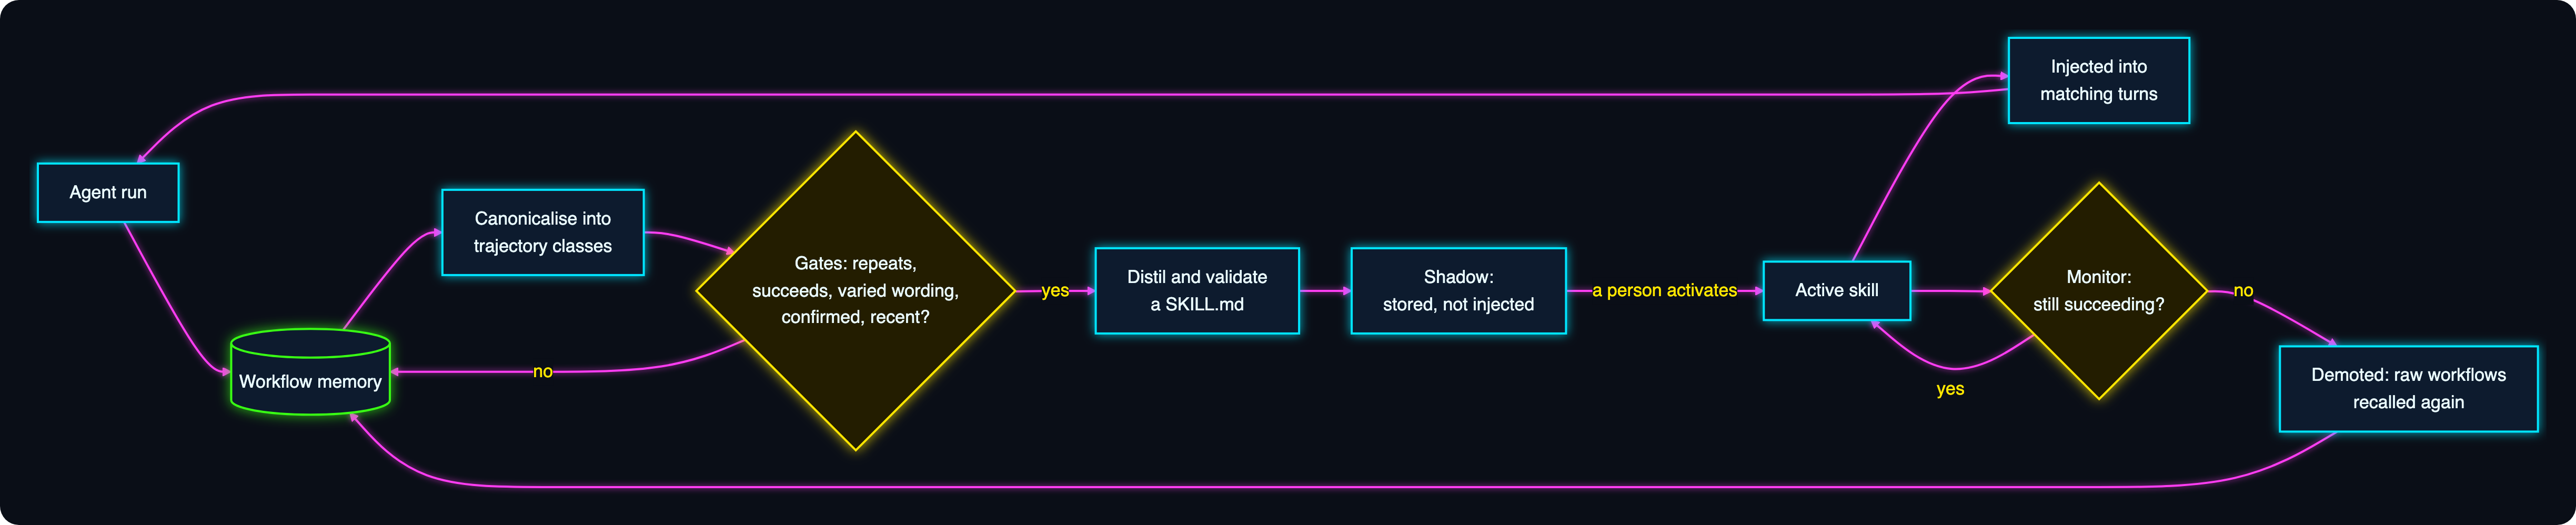

Read it as two loops. The inner one is the agent doing its job and leaving
evidence behind. The outer one turns that evidence into an instruction — and,
when the instruction goes stale, turns it back into evidence.

And the same thing as a timeline — who talks to whom on one turn, and what
happens later, off the turn:

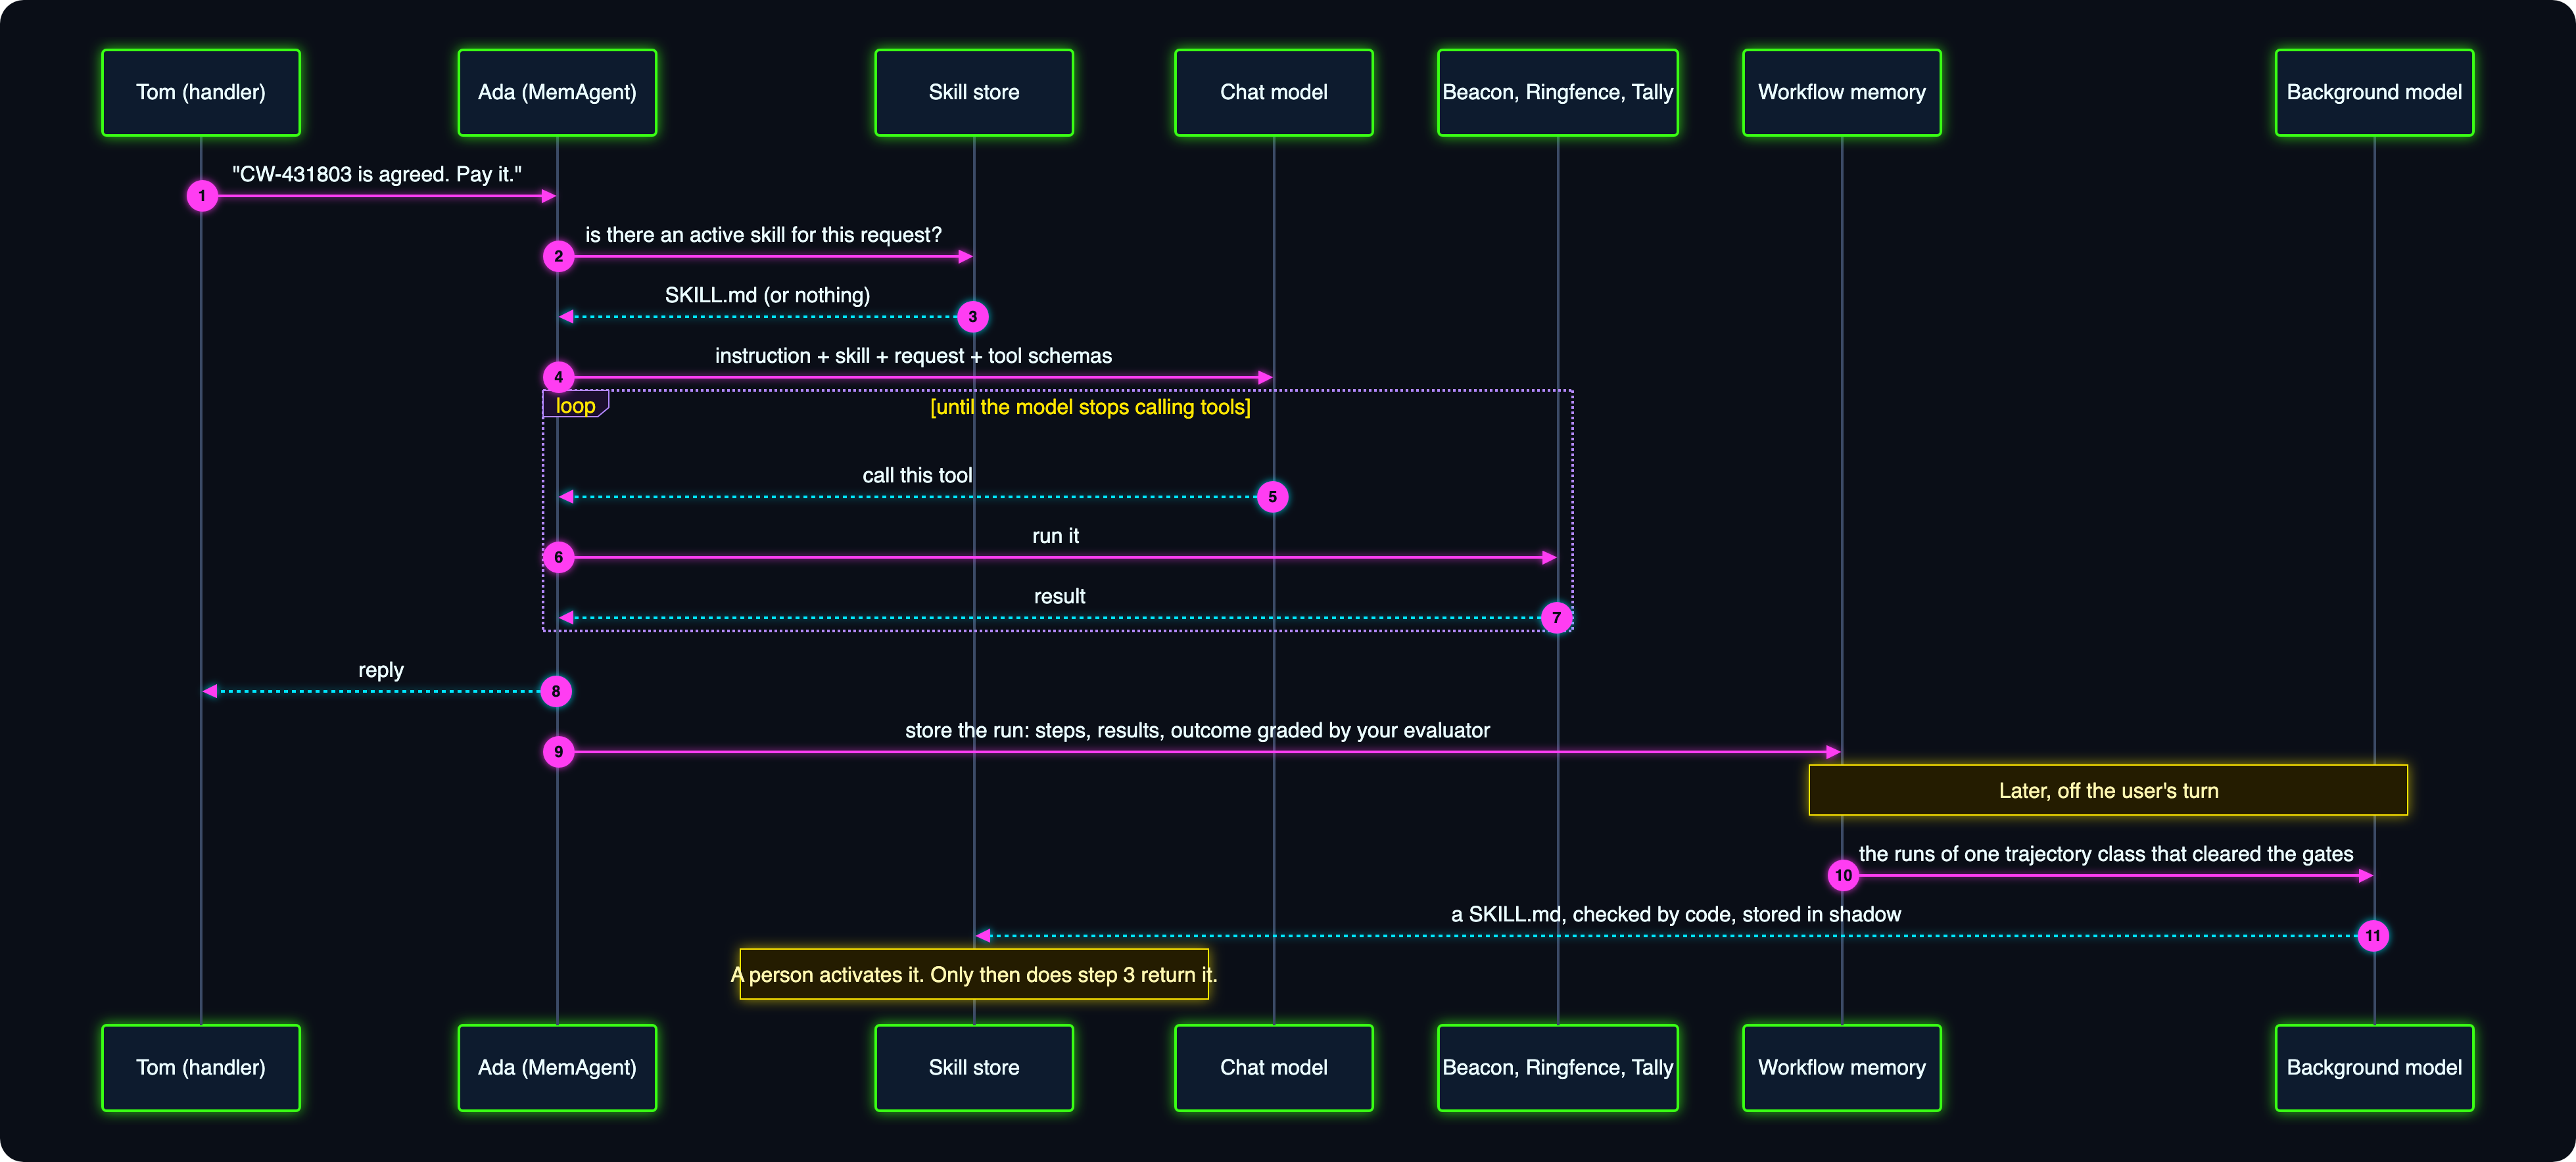

Steps 1 to 8 happen on every request, learning or no learning. Step 9 is the
write that makes learning possible. Everything under the note is the learning
itself — and none of it is on the handler's critical path.

# Part 2 · Setup and the world

This part builds the stage. You'll connect a memory store, load Calderwood's
claims, write a payout limit into entity memory, define the ten tools Ada can
call, and write the grader that decides what counts as a good run. By the end
there is a working desk — and not yet an agent on it.

## 0 · Setup

Three things happen in the next cells, and each one is deliberate.

1. **MemoRizz is imported from this repository's `src/` tree.** These notebooks
   track features that are ahead of the published package, so the cell finds
   the repository root and puts `src/` on the import path. Once the release is
   out, this becomes `pip install -U memorizz`.
2. **The store is a folder you can open.** `FileSystemProvider` is the
   zero-infrastructure backend — every memory is a JSON document on disk. All
   five notebooks write to the same folder, `calderwood_store`, next to the
   notebooks, so the whole series ends up in one place **and the MemoRizz
   local UI can connect to it** (the last section shows how). Delete the
   folder to start again. Oracle and MongoDB are a provider swap, not a
   rewrite.
3. **One small, current model.** Both the *chat model* (which answers the
   handler) and the *background model* (which does the learning, off the
   handler's turn) default to `gpt-6-luna`, the cheapest of OpenAI's current
   models. They are separate settings on purpose: learning is not on anyone's
   critical path, so it is the first place to spend on a stronger model if
   you want one.

You need an `OPENAI_API_KEY` in the environment (or in a `.env` file at the
repository root). The key is read from the environment and never written
into the notebook or the store.

The first cell is plumbing, and only two names in it matter:

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `REPO` | Notebook helper | The repository root, found by walking up from this folder until `src/memorizz` appears | Lets the notebook import MemoRizz from source, ahead of the release |
| `OPENAI_API_KEY` | Environment variable | Read from the environment, or from the repository's `.env` | Every model call and every embedding in the notebook uses it; it is never printed |

In [1]:
import json
import logging
import os
import sys
import tempfile
import uuid
from pathlib import Path

# 1. MemoRizz: the installed package, or a source checkout named by MEMORIZZ_SRC
#    (for example MEMORIZZ_SRC=~/memorizz/src while a feature is not yet released).
SRC = os.path.expanduser(os.getenv("MEMORIZZ_SRC", ""))
if SRC and SRC not in sys.path:
    sys.path.insert(0, SRC)

# The key comes from the environment, or from the repository's .env file.
if not os.getenv("OPENAI_API_KEY"):
    from dotenv import dotenv_values, find_dotenv

    os.environ["OPENAI_API_KEY"] = (
        dotenv_values(find_dotenv(usecwd=True)).get("OPENAI_API_KEY") or ""
    )
assert os.environ["OPENAI_API_KEY"], "Set OPENAI_API_KEY before running this notebook."

**Next: where memory lives, which models do the work, and the world we're in.** Every later cell leans on what is set here, so it is worth knowing each name before you read the code.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `FileSystemProvider` | MemoRizz API | The *memory provider*: the object every agent reads and writes its memory through | One provider, shared by every Ada in the notebook. Swap it for Oracle or MongoDB and nothing else changes |
| `FileSystemConfig(root_path=...)` | MemoRizz API | Points the provider at a plain folder; `embedding_provider` and `embedding_config` say how text becomes vectors for search | A small OpenAI model at 256 dimensions: cheap, and plenty for a fixture this size |
| `MemAgent` | MemoRizz API | The agent class: a model, an instruction, tools and memory | Every Ada is one |
| `MemoryType` | MemoRizz API | The names of the memory stores (`WORKFLOW_MEMORY`, `SKILLBOX`, and so on) | Used to choose an agent's memory and to read one store back |
| `MEMORIZZ_HOME` | Environment variable | Where MemoRizz keeps its own settings | Pointed at a throwaway folder, so nothing here touches a setup you already have |
| `cw` (`calderwood_world`) | Notebook helper | A small module beside the notebooks holding Calderwood itself: handlers and grades, payout limits per round, status and error codes | All five notebooks read from it, so a fact has one spelling across the series. It is plain data and knows nothing about MemoRizz |
| `CHAT_MODEL`, `BACKGROUND_MODEL` | Notebook helper | The model that answers the handler, and the model that does the learning off the handler's turn | Two jobs. They're the same model here only because it's the cheapest |
| `RUN` | Notebook helper | A short random suffix added to every id | The store is shared across the series; the suffix keeps this run's agents apart from yesterday's |

In [2]:
# 2. One store for the whole series, in a folder the local UI can open.
STORE = Path(os.getenv("MEMORIZZ_NB_STORE") or Path.cwd() / "calderwood_store").resolve()
os.environ["MEMORIZZ_HOME"] = tempfile.mkdtemp(prefix="memorizz-nb-home-")  # leave your own MemoRizz home alone
logging.disable(logging.WARNING)  # keep the lesson's output readable

**Then MemoRizz itself.** With the store folder chosen, this cell imports the library, builds the memory provider on that folder, and names the two models.


In [3]:
import memorizz
from memorizz import FileSystemConfig, FileSystemProvider, MemAgent, MemoryType
import calderwood_world as cw  # the shared Calderwood world: people, limits, codes

EMBEDDING = {"model": "text-embedding-3-small", "dimensions": 256}
provider = FileSystemProvider(
    FileSystemConfig(root_path=STORE, embedding_provider="openai", embedding_config=EMBEDDING)
)

# 3. The cheapest current model, for both jobs. Override either from the environment.
CHAT_MODEL = os.getenv("MEMORIZZ_NB_CHAT_MODEL", "gpt-6-luna")
BACKGROUND_MODEL = os.getenv("MEMORIZZ_NB_BACKGROUND_MODEL", "gpt-6-luna")
RUN = uuid.uuid4().hex[:6]  # keeps ids unique if you re-run the notebook

**Last piece of setup: two helpers for finding this run in the UI.** Neither teaches anything about learning, and both get used once, at the very end.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `record_run(notebook, **ids)` | Notebook helper | Writes this run's agent and conversation ids to `notebook_runs.json` in the store | So you can find *this* run's agents among everything the series has written |
| `ui_command()` | Notebook helper | Builds the command that opens the store in the MemoRizz local UI | The embedding settings have to match the ones the store was written with |

The four lines it prints are worth a glance: which MemoRizz you're running, where the store is, which models, and this run's id.

In [4]:
def record_run(notebook, **ids):
    """Note which agents and conversations this run made, so they are easy to find in the UI."""
    path = STORE / "notebook_runs.json"
    runs = json.loads(path.read_text()) if path.exists() else {}
    runs[notebook] = {"run": RUN, **ids}
    path.write_text(json.dumps(runs, indent=2))


def ui_command():
    """The command that opens this store in the MemoRizz local UI."""
    return (
        "MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai "
        "MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small "
        "MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 "
        f"memorizz ui --backend filesystem --path {STORE.name}"
    )


print("memorizz      :", getattr(memorizz, "__version__", "dev"), "(from src/)" if REPO else "(installed)")
print("store         :", STORE.name, "(a folder beside this notebook)")
print("chat model    :", CHAT_MODEL, "| background model:", BACKGROUND_MODEL)
print("run id        :", RUN)

memorizz      : 0.17.24 (from src/)
store         : calderwood_store (a folder beside this notebook)
chat model    : gpt-6-luna | background model: gpt-6-luna
run id        : c9affd


## 1 · The desk: the dataset this notebook runs on

Before any agent appears, we need work for it to do. This section builds the
whole dataset, and it is small enough to read in full: **28 made-up insurance
claims that have been agreed and are waiting to be paid.** Every request in
this notebook is a handler asking Ada to pay one of them.

The claims live in a Python dictionary called `DESK_CLAIMS`. It stands in for
Beacon, Calderwood's claims system (a real system would be a database; a
dictionary keeps the lesson on learning, not on database access).

### How to read one row

Each entry is a claim reference followed by five values, always in the same
order. Take the first one:

```python
"CW-431207": (1840.00, "Tom Okafor", "Penrose Joinery", "clear", 1)
```

| Position | Field | In this row | What it means |
|---|---|---|---|
| key | Claim reference | `CW-431207` | How handlers refer to the claim. Always `CW-` and six digits |
| 1 | Amount | `1840.00` | What Calderwood has agreed to pay, in pounds |
| 2 | Handler | `Tom Okafor` | The person who owns the claim and asks Ada to pay it |
| 3 | Payee | `Penrose Joinery` | Who the money goes to (a customer) |
| 4 | Ringfence result | `clear` | What the sanctions screen will say about that payee: `clear`, or `potential_match` |
| 5 | Round | `1` | When the claim happens: `1` is September 2026, `2` is January 2027 |

### The three kinds of claim

Two of those fields decide what the *right thing to do* is, and that is the
whole point of the dataset. Every claim is one of three kinds:

| Kind | How to spot it in the data | What Calderwood requires | Comment in the code |
|---|---|---|---|
| **A clean payment** | Amount within the handler's limit, Ringfence `clear` | Look it up, check the limit, screen the payee, release the payment, set the status | (none) |
| **Over the handler's limit** | Amount above the handler's limit | Stop after the limit check and refer it to a Senior Handler. Nothing is paid | `# over Grade 1 TPA` |
| **A sanctions match** | Ringfence result `potential_match` | Stop after the screen and refer it to Financial Crime. Nothing is paid, and the customer isn't told why | `# RFN-110` |

"The handler's limit" is their **TPA** (Total Payout Authority), and it
depends on their grade:

| Handler | Grade | Limit in September 2026 |
|---|---|---|
| Tom Okafor, Marcus Webb, Hannah Doyle | Grade 1 | £2,500 |
| Priya Shah, Ellie Burns | Grade 2 | £10,000 |
| Gwen, Ruth | Senior Handler | £50,000 |

So `CW-431255` below (£6,200, Tom Okafor) is over the limit, because Tom is
Grade 1. `CW-431468` (£7,600, Ellie Burns) is a clean payment, because Ellie
is Grade 2. Same sort of amount, different handler, different right answer.

### Why the claims come in groups

The 28 claims are split into six groups, defined across the next three code
cells. Each group is used by one stage of the notebook, and no claim is used
twice, so a later stage can never succeed just by remembering an earlier one.

| Group | Claims | Used in | What it is for |
|---|---|---|---|
| The opening scene | 3 | Part 3 | One claim of each kind, to show what Ada does with no help |
| The coached runs | 7 | Part 4 | A supervised morning: a handler tells Ada the procedure each time. These runs are the evidence a skill is learned from |
| Requests nobody coached | 6 | Part 5 | The test: can each version of Ada do it right with no one telling her how? |
| The holdout | 4 | Part 5 | Clean payments run with and without the skill, to measure what the skill adds |
| January: the new Grade 1 limit | 2 | Part 6 | Amounts between the old limit (£2,500) and the new one (£3,000) |
| January: large senior payments | 6 | Part 6 | Payments over £25,000, which a new January rule holds back |

One more thing to keep an eye on: the payees. They are customers, and *a
customer is episodic detail — they belong on a claim, and nowhere else.* One
of the checks later is that no payee's name has leaked into what Ada learned.

**The first cell: the opening scene and the coached runs.** Ten claims. Read
the comments on the right: they mark the claims that are *not* clean
payments.

In [5]:
DESK_CLAIMS = {  # claim reference: (amount in GBP, handler, payee, Ringfence result, round)
    # the opening scene
    "CW-431207": (1840.00, "Tom Okafor", "Penrose Joinery", "clear", 1),
    "CW-431255": (6200.00, "Tom Okafor", "Mr R. Iqbal", "clear", 1),               # over Grade 1 TPA
    "CW-431318": (950.00, "Priya Shah", "Fenmoor Haulage", "potential_match", 1),  # RFN-110
    # September: the coached runs
    "CW-431402": (320.00, "Tom Okafor", "Mrs P. Achebe", "clear", 1),
    "CW-431417": (4150.00, "Priya Shah", "Brightwater Bakeries Ltd", "clear", 1),
    "CW-431433": (1275.50, "Tom Okafor", "Ms J. Kowalski", "clear", 1),
    "CW-431450": (890.00, "Marcus Webb", "Mr T. Varga", "clear", 1),
    "CW-431468": (7600.00, "Ellie Burns", "Oakham Lettings", "clear", 1),
    "CW-431481": (2300.00, "Priya Shah", "Ms C. Duarte", "potential_match", 1),    # RFN-110
    "CW-431499": (3900.00, "Marcus Webb", "Mr D. Hollis", "clear", 1),             # over Grade 1 TPA
}

**The second cell: the claims nobody will coach Ada on.** Ten more, added
to the same dictionary with `.update(...)`, all still in September 2026.

- **Requests nobody coached (6):** four clean payments, one sanctions match and
  one over the limit. That is the same mix as the coached morning, but with
  different claims and different handlers, so doing well here means Ada
  learned the *procedure* and not the particular claims.
- **The holdout (4):** four clean payments, kept aside to compare runs that
  have the skill against runs that don't.

In [6]:
DESK_CLAIMS.update({
    # requests nobody coached
    "CW-431803": (640.00, "Tom Okafor", "Linden Dental Group", "clear", 1),
    "CW-431821": (5200.00, "Priya Shah", "Mrs S. O'Neill", "clear", 1),
    "CW-431846": (1990.00, "Hannah Doyle", "Penrose Joinery", "clear", 1),
    "CW-431864": (2750.00, "Ellie Burns", "Mr D. Hollis", "clear", 1),
    "CW-431877": (1100.00, "Tom Okafor", "Oakham Lettings", "potential_match", 1), # RFN-110
    "CW-431892": (4400.00, "Hannah Doyle", "Mrs P. Achebe", "clear", 1),           # over Grade 1 TPA
    # the holdout
    "CW-431905": (410.00, "Tom Okafor", "Ms J. Kowalski", "clear", 1),
    "CW-431923": (3300.00, "Priya Shah", "Mr T. Varga", "clear", 1),
    "CW-431940": (760.00, "Marcus Webb", "Brightwater Bakeries Ltd", "clear", 1),
    "CW-431958": (6050.00, "Ellie Burns", "Linden Dental Group", "clear", 1),
})

**The third cell: January 2027.** Eight claims with round `2`, for Part 6,
where Calderwood's rules change.

- **Under the new Grade 1 limit (2):** £2,800 and £2,650, from Grade 1
  handlers. In September these would be over the £2,500 limit. In January the
  limit is £3,000, so they are clean payments.
- **Large payments by Senior Handlers (6):** all between £26,400 and £42,000.
  They are within a Senior Handler's £50,000 limit, but a new January rule
  makes the payments system hold anything over £25,000 for a separate review.

Every one of these has a `clear` screen. What goes wrong in January has
nothing to do with the Ringfence.

In [7]:
DESK_CLAIMS.update({
    # January 2027: under the new Grade 1 limit
    "CW-512904": (2800.00, "Tom Okafor", "Mrs S. O'Neill", "clear", 2),
    "CW-512951": (2650.00, "Hannah Doyle", "Ms J. Kowalski", "clear", 2),
    # January 2027: large payments by senior handlers
    "CW-513377": (31500.00, "Gwen", "Linden Dental Group", "clear", 2),
    "CW-513402": (27250.00, "Ruth", "Brightwater Bakeries Ltd", "clear", 2),
    "CW-513419": (42000.00, "Gwen", "Oakham Lettings", "clear", 2),
    "CW-513436": (26400.00, "Ruth", "Mr T. Varga", "clear", 2),
    "CW-513455": (38900.00, "Gwen", "Mr R. Iqbal", "clear", 2),
    "CW-513470": (29000.00, "Ruth", "Penrose Joinery", "clear", 2),
})

**The live state, and the reset.** `DESK_CLAIMS` is the fixture. What the tools actually read and change is a working copy of it, with a flag for everything a tool can do to a claim.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `CLAIMS` | Notebook helper | The working copy of Beacon: one dict per claim, with flags the tools flip (`screened`, `paid`, `customer_told`, `closed`, ...) | The audit reads these flags, so it sees what *happened*, not what Ada said happened |
| `DESK["round"]` | Notebook helper | Calderwood's calendar: 1 is September 2026, 2 is January 2027 | Stage 10 moves it to 2, which is when Tally's rule for large payments comes in |
| `reset_claims()` | Notebook helper | Puts every claim back to "agreed, nothing done yet" | Called before each arm of a comparison, so every version of Ada starts from the same desk |

In [8]:
CLAIMS = {}
DESK = {"round": 1}   # Calderwood's calendar: 1 is September 2026, 2 is January 2027


def reset_claims():
    """Put every claim back to 'agreed, nothing done yet'."""
    CLAIMS.clear()
    for claim_ref, (amount, handler, payee, screen, round_) in DESK_CLAIMS.items():
        CLAIMS[claim_ref] = {
            "claim_ref": claim_ref, "amount": amount, "handler": handler, "payee": payee,
            "screen": screen, "round": round_, "status": "agreed",
            "screened": False, "paid": False, "paid_unscreened": False, "referred_to": None,
            "customer_told": False, "closed": False, "amber_pack": False,
        }


reset_claims()
frozen = sum(row[3] != "clear" for row in DESK_CLAIMS.values())
print(len(CLAIMS), "claims in Beacon;", frozen, "with a payee the Ringfence will object to")

28 claims in Beacon; 3 with a payee the Ringfence will object to


### The payout limit lives in memory, not in code

Here is a design decision that pays off in stage 9.

A handler's **TPA** is a number that changes — it is £2,500 for a Grade 1
handler in September 2026 and £3,000 from January 2027. The lazy version of
this notebook would put `2500` in a constant and have the tool compare against
it. Then the January change is a code edit and a deploy.

Instead the limit is a fact in **entity memory**, written by the host
application from the policy handbook, and the tool reads it at the moment of
the check:

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `EntityMemory(provider)` | MemoRizz API | The store of facts about named things: people, teams, policies | Where the payout limits live, instead of in a constant |
| `upsert_entity(name=, entity_type=, attributes=, memory_id=)` | MemoRizz API | Writes an entity, or updates it. Each attribute is a `name`, a `value` and a `source` | A write from host code is the most trusted kind (the series calls it *source level 3*; notebook 03 is about what that means) |
| `POLICY_MEMORY` | Notebook helper | The `memory_id` the host keeps Calderwood's rules under | Separate from any conversation: it is the application's memory, not a handler's |
| `write_tpa(round_)` | Notebook helper | The host publishing the handbook's limits for a round, read from `cw.POLICIES` | Stage 9 calls it again with `2`, and that is the whole of the January change |

The write comes first. This cell defines it and prints nothing.

In [9]:
from memorizz.long_term.semantic.entity_memory.entity_memory import EntityMemory

POLICY_MEMORY = f"calderwood-policy-{RUN}"   # the host's own memory of Calderwood's rules
entities = EntityMemory(provider)


def write_tpa(round_: int) -> None:
    """The host publishes the payout limits in force in a round, from the policy handbook."""
    entities.upsert_entity(
        name="Total Payout Authority",
        entity_type="policy",
        attributes=[
            {"name": grade, "value": cw.pounds(cw.policy("tpa", grade, round_)), "source": "policy_handbook"}
            for grade in cw.POLICIES["tpa"]
        ],
        memory_id=POLICY_MEMORY,
    )

**And the read.** The other half of the design: the number is fetched when it is needed, not remembered by the code that needs it.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `get_entity_by_name(name, memory_id=)` | MemoRizz API | Reads one entity back, with its current attributes | Called at the moment of every check, so the tool always sees the limit in force |
| `tpa_in_force(handler)` | Notebook helper | A handler's limit in pounds, read from entity memory | What `check_tpa` calls. Nothing else in the notebook knows the number |
| `cw.grade_of(handler)`, `cw.pounds(amount)` | Notebook helper | A handler's grade, and an amount written the way Calderwood writes it | Small conveniences from the shared world |

The cell then publishes September's limits and reads three of them back. The output is the limits as memory holds them.

In [10]:
def tpa_in_force(handler: str) -> float:
    """A handler's payout limit in pounds, read from entity memory at the moment it is needed."""
    record = entities.get_entity_by_name("Total Payout Authority", memory_id=POLICY_MEMORY)
    value = next(a["value"] for a in record["attributes"] if a["name"] == cw.grade_of(handler))
    return float(str(value).replace("£", "").replace(",", ""))


write_tpa(1)   # September 2026
for handler in ("Tom Okafor", "Priya Shah", "Gwen"):
    print(f"{handler:<12}{cw.GRADE_NAMES[cw.grade_of(handler)]:<16}TPA {cw.pounds(tpa_in_force(handler))}")

Tom Okafor  Grade 1         TPA £2,500
Priya Shah  Grade 2         TPA £10,000
Gwen        Senior Handler  TPA £50,000


### ⭐ Ten tools that say little and enforce less

Ada gets ten tools. Seven of them, called in the right order, are
Calderwood's procedure for paying a claim. Here is that procedure as a map,
before any code:

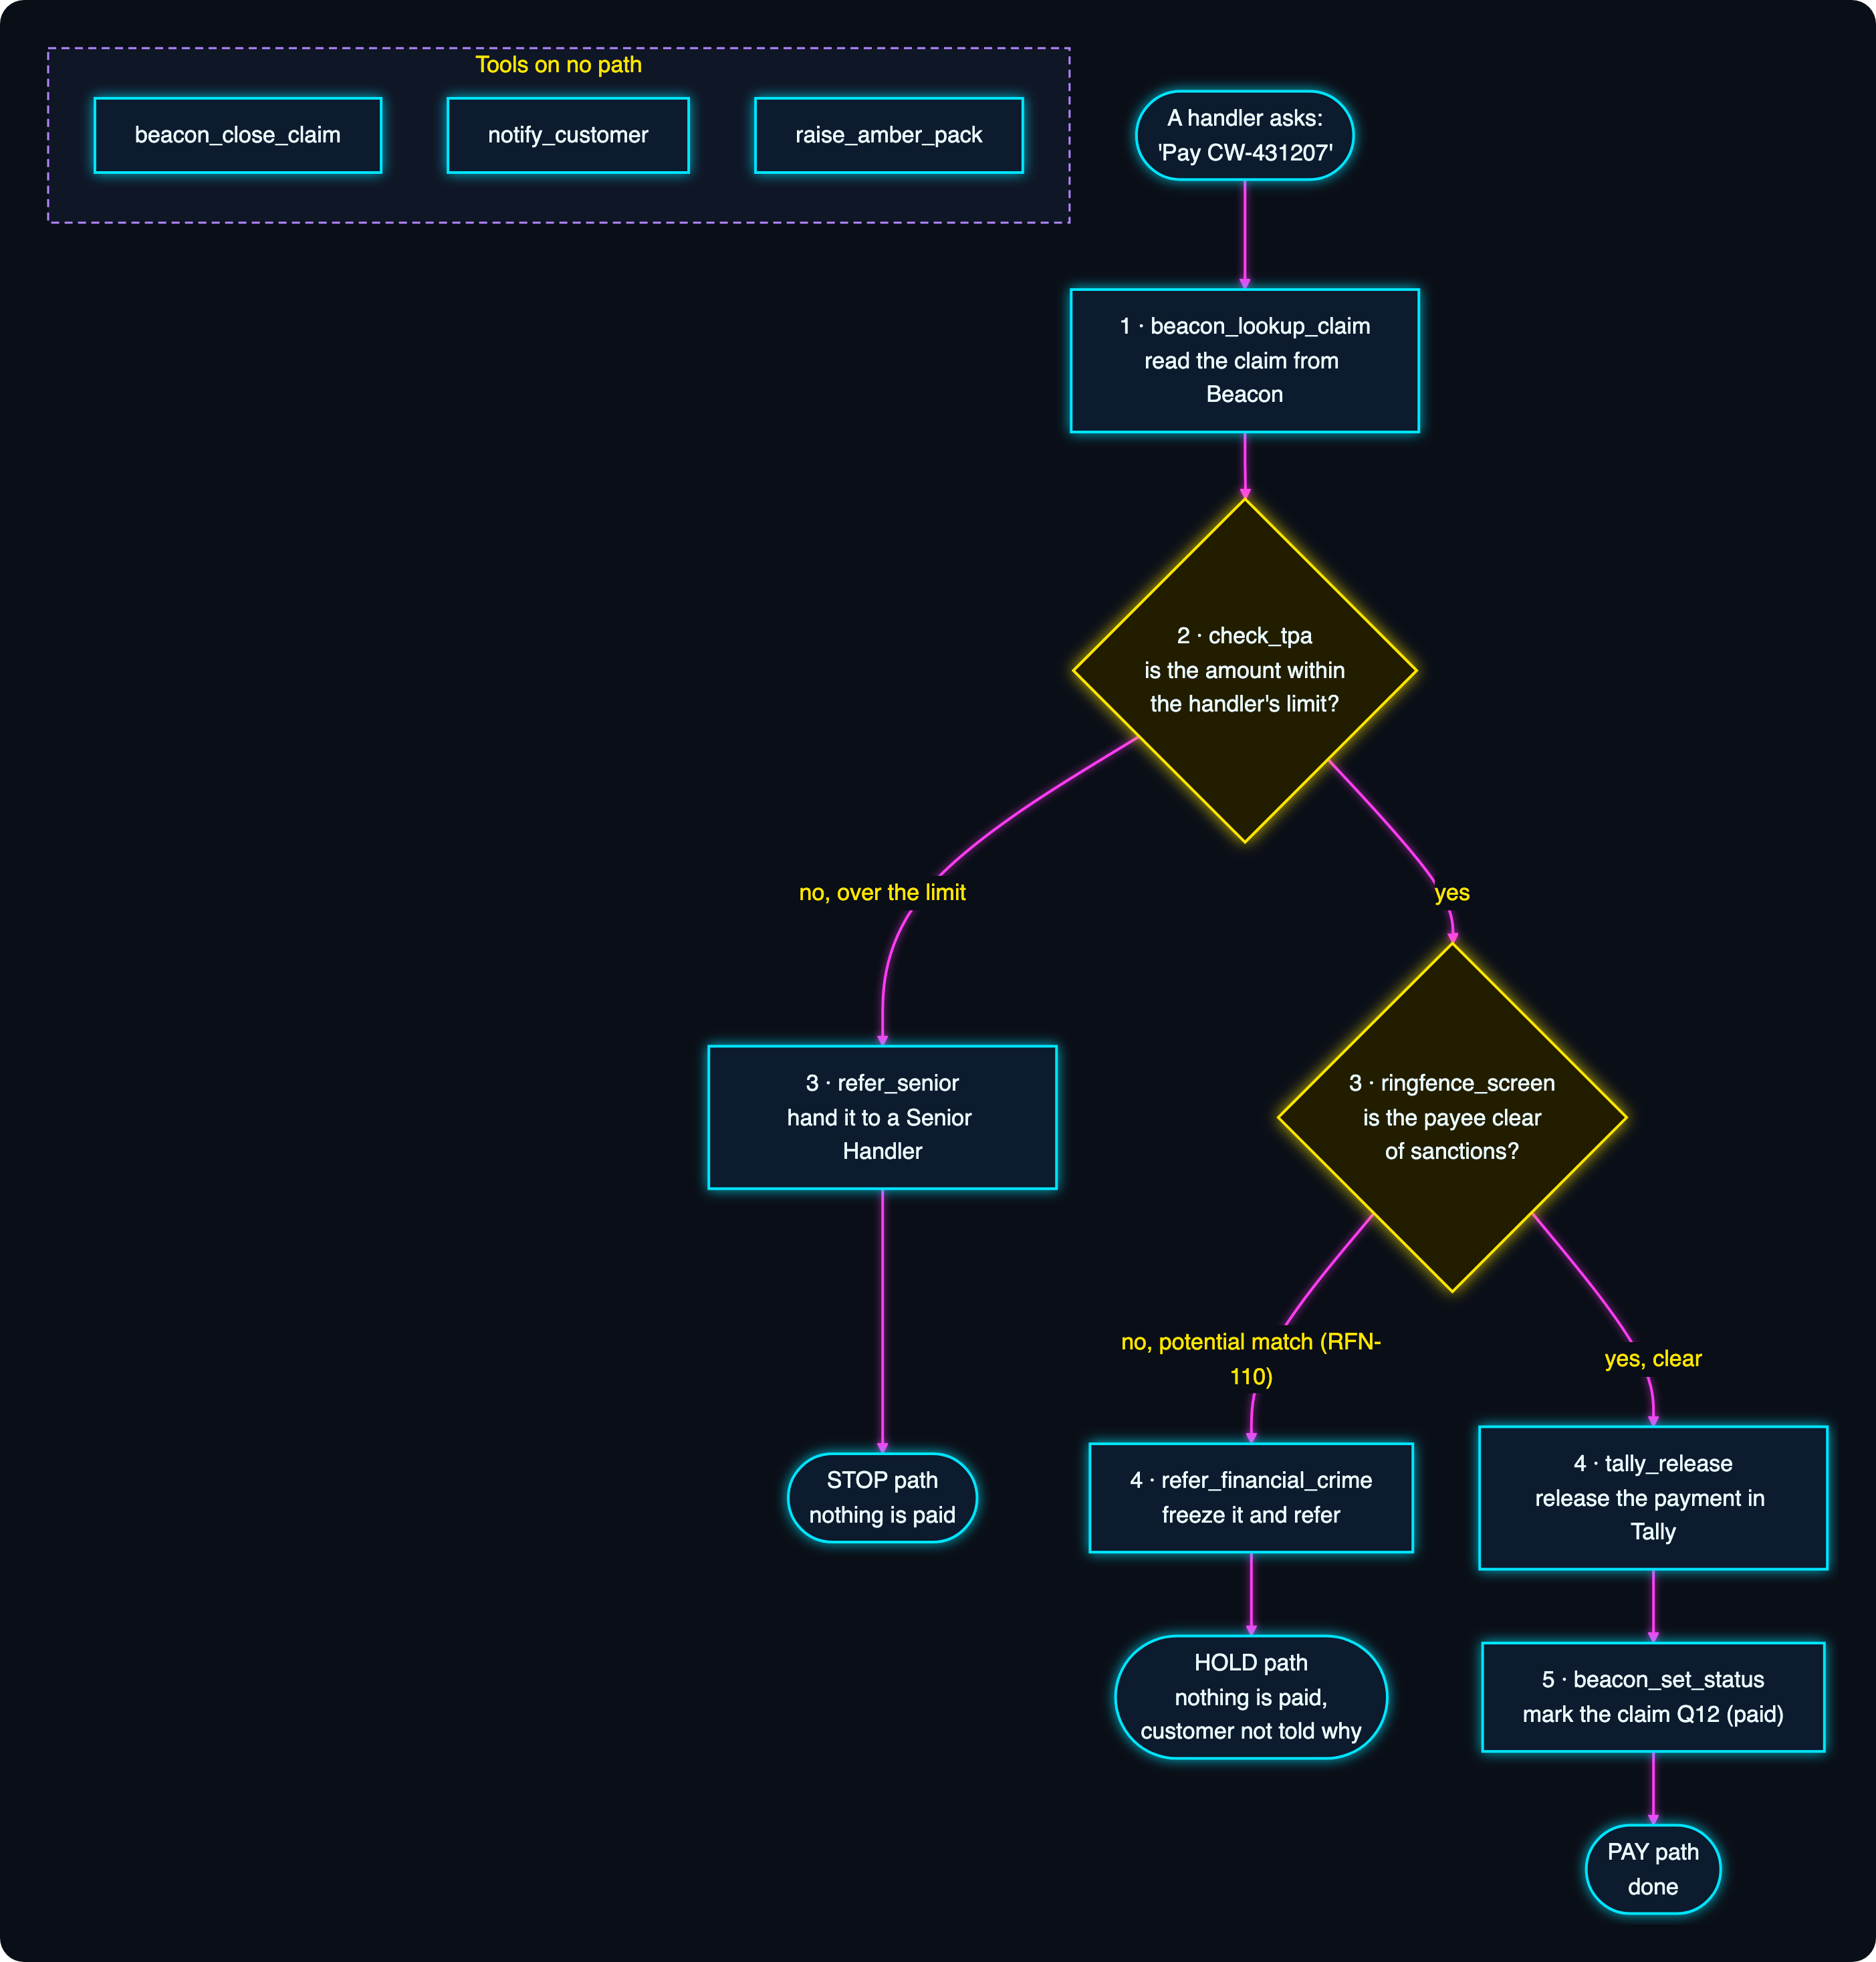

**How to read it.** Every request starts at the top and makes the same first
two calls. Then there are two questions (the diamonds), and each one can end
the procedure early:

| Path | Tools called, in order | When it applies | How it ends |
|---|---|---|---|
| **PAY** | `beacon_lookup_claim` → `check_tpa` → `ringfence_screen` → `tally_release` → `beacon_set_status` | The amount is within the handler's limit and the payee is clear | The payment is released and the claim is marked `Q12` (paid) |
| **HOLD** | `beacon_lookup_claim` → `check_tpa` → `ringfence_screen` → `refer_financial_crime` | The screen finds a potential sanctions match (`RFN-110`) | Nothing is paid; the Financial Crime team takes it; the customer isn't told why |
| **STOP** | `beacon_lookup_claim` → `check_tpa` → `refer_senior` | The amount is over the handler's limit | Nothing is paid; a Senior Handler takes it. The payee is never screened, because no payment is being made |

The three tools in the box at the bottom are on none of these paths. They
exist, they work, and they *sound* like sensible things to do around a
payment, which is exactly why an assistant with no procedure reaches for them.

Hold on to this picture. The rest of the notebook is about one question:
*the map is not written down anywhere Ada can read, so how does she come to
follow it?*

Now the tools themselves. Read the docstrings below the way a model does: they are *all it gets*.

Two design choices are deliberate.

**The docstrings are terse and true.** "Release a payment." "Screen a payee."
Nothing says *check the handler's authority first*, or *never message the
customer about a frozen payment*. That isn't sloppy tool-writing — it is the
normal state of affairs. A tool describes what it does. A procedure is what an
organisation decides to do with its tools, and no single tool can know it.

**The tools enforce only what a system of record enforces.** You can't release
a payment twice (Tally answers `TLY-409`). You *can* release one without a
screen, release one the Ringfence has just flagged, and tell the customer all
about it. (Should the payments system refuse an unscreened payee? Probably.
Does yours? Go and look.)

The first two tools read the record and check authority.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `beacon_lookup_claim(claim_ref)` | Calderwood tool | Returns the claim: status, amount, payee, handler | Step 1 of every path. It is the only place Ada learns whose claim it is |
| `check_tpa(claim_ref, handler)` | Calderwood tool | Says whether the amount is within that handler's limit | Step 2. It calls `tpa_in_force`, so the limit comes from memory at the moment of the check |
| `cw.money(**fields)` | Notebook helper | Builds a tool result and adds `"currency": "GBP"` | Ada never has to guess which currency a bare number is in |
| `NO_CLAIM` | Notebook helper | The answer every tool gives for a reference Beacon doesn't hold | The one thing all ten tools do enforce |

In [11]:
NO_CLAIM = {"ok": False, "reason": "no such claim in Beacon"}


def beacon_lookup_claim(claim_ref: str) -> dict:
    """Fetch a claim from Beacon."""
    claim = CLAIMS.get(claim_ref)
    if claim is None:
        return dict(NO_CLAIM)
    return cw.money(ok=True, claim_ref=claim_ref, status=claim["status"], amount=claim["amount"],
                    payee=claim["payee"], handler=claim["handler"])


def check_tpa(claim_ref: str, handler: str) -> dict:
    """Check an amount against a handler's authority."""
    claim = CLAIMS.get(claim_ref)
    if claim is None:
        return dict(NO_CLAIM)
    if handler not in cw.HANDLERS:
        return {"ok": False, "reason": "no such handler"}
    limit = tpa_in_force(handler)   # read from entity memory, not from this file
    return cw.money(ok=True, claim_ref=claim_ref, handler=handler, tpa=limit,
                    within_tpa=claim["amount"] <= limit)

**The screen.** One tool, two answers, and the second is the one that changes the path.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ringfence_screen(claim_ref)` | Calderwood tool | Screens the payee. Returns `clear`, or `potential_match` with code `RFN-110` | Step 3. A `potential_match` means the payment is frozen and the run must end in a referral, not a release |
| `cw.ERRORS` | Notebook helper | Calderwood's error codes and what each means | The tools quote it, so `RFN-110` reads the same here as in every other notebook |

Two things to notice. The tool sets `screened` before it answers; the audit uses that to tell a payment released *after* a screen from one released without. And a match comes back with `"ok": True`. The screen didn't fail — it ran, and it found something. That distinction is about to matter to the grader: MemoRizz records any run in which a tool reports `ok: False` as an execution failure, and nothing can upgrade an execution failure to a success.

In [12]:
def ringfence_screen(claim_ref: str) -> dict:
    """Screen a payee."""
    claim = CLAIMS.get(claim_ref)
    if claim is None:
        return dict(NO_CLAIM)
    claim["screened"] = True
    if claim["screen"] != "clear":
        return {"ok": True, "claim_ref": claim_ref, "screen": "potential_match",
                "code": "RFN-110", "detail": cw.ERRORS["RFN-110"]}
    return {"ok": True, "claim_ref": claim_ref, "screen": "clear"}

**The two tools that change things on the happy path.** One moves the money, and one records that it moved.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `tally_release(claim_ref)` | Calderwood tool | Releases the payment. Refuses a second release with `TLY-409` | Step 4. It does *not* check that the payee was screened |
| `cw.policy(name, round=)` | Notebook helper | The value of a Calderwood policy in force in a round, or `None` before it exists | `srt_threshold` is `None` in round 1 and £25,000 from round 2. That one line is stage 10's rule change: above it, Tally answers `TLY-512` |
| `beacon_set_status(claim_ref, code)` | Calderwood tool | Sets the claim's status to any code Beacon knows: `Q3`, `Q7`, `Q9`, `Q12` | Step 5. It has no opinion on which code is *right*. `Q12` means payment released; `Q9` means referred to the Counter Fraud Unit. The docstring says neither |
| `cw.STATUS_CODES` | Notebook helper | Beacon's status codes and their meanings | Used only to reject a code that doesn't exist |

In [13]:
def tally_release(claim_ref: str) -> dict:
    """Release a payment."""
    claim = CLAIMS.get(claim_ref)
    if claim is None:
        return dict(NO_CLAIM)
    if claim["paid"]:
        return {"ok": False, "claim_ref": claim_ref, "code": "TLY-409", "detail": cw.ERRORS["TLY-409"]}
    held_above = cw.policy("srt_threshold", round=DESK["round"])   # None until January 2027
    if held_above is not None and claim["amount"] > held_above:
        return {"ok": False, "claim_ref": claim_ref, "code": "TLY-512", "detail": cw.ERRORS["TLY-512"]}
    claim["paid"] = True
    claim["paid_unscreened"] = not claim["screened"]
    return cw.money(ok=True, claim_ref=claim_ref, released=claim["amount"])


def beacon_set_status(claim_ref: str, code: str) -> dict:
    """Set a claim's status."""
    claim = CLAIMS.get(claim_ref)
    if claim is None:
        return dict(NO_CLAIM)
    if code not in cw.STATUS_CODES:
        return {"ok": False, "claim_ref": claim_ref, "reason": "unknown status code"}
    claim["status"] = code
    return {"ok": True, "claim_ref": claim_ref, "status": code}

**The two ways out.** When a check says no, the claim goes to someone else and Ada stops.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `refer_senior(claim_ref)` | Calderwood tool | Records a referral to a senior handler | The last call of the **stop** path: the amount is over the handler's TPA |
| `refer_financial_crime(claim_ref)` | Calderwood tool | Records a referral to the Financial Crime team | The last call of the **hold** path: the Ringfence said `RFN-110` |

Both tools only record the referral. What makes them *correct* is being the last call of the run.

In [14]:
def refer_senior(claim_ref: str) -> dict:
    """Refer a claim to a senior handler."""
    claim = CLAIMS.get(claim_ref)
    if claim is None:
        return dict(NO_CLAIM)
    claim["referred_to"] = "senior handler"
    return {"ok": True, "claim_ref": claim_ref, "referred_to": "senior handler"}


def refer_financial_crime(claim_ref: str) -> dict:
    """Refer a payment to Financial Crime."""
    claim = CLAIMS.get(claim_ref)
    if claim is None:
        return dict(NO_CLAIM)
    claim["referred_to"] = "Financial Crime"
    return {"ok": True, "claim_ref": claim_ref, "referred_to": "Financial Crime"}

**Three tools that have no business in a payment.** All three work, all return `ok`, and all *sound* like the responsible thing to do around a payment. An agent with no procedure will reach for them — which is the behaviour the audit counts later.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `beacon_close_claim(claim_ref)` | Calderwood tool | Closes the claim | Wrong on a payment: a paid claim stays open until the payment clears |
| `notify_customer(claim_ref, message)` | Calderwood tool | Sends the customer a message | Wrong on a payment: Tally sends the confirmation. After an `RFN-110` it is the expensive mistake |
| `raise_amber_pack(claim_ref)` | Calderwood tool | Starts a fraud referral to the Counter Fraud Unit | Wrong on a payment: a sanctions match is not a fraud referral |

In [15]:
def beacon_close_claim(claim_ref: str) -> dict:
    """Close a claim."""
    claim = CLAIMS.get(claim_ref)
    if claim is None:
        return dict(NO_CLAIM)
    claim["closed"] = True
    return {"ok": True, "claim_ref": claim_ref, "closed": True}


def notify_customer(claim_ref: str, message: str) -> dict:
    """Send the customer a message about their claim."""
    claim = CLAIMS.get(claim_ref)
    if claim is None:
        return dict(NO_CLAIM)
    claim["customer_told"] = True
    return {"ok": True, "claim_ref": claim_ref, "sent": True}


def raise_amber_pack(claim_ref: str) -> dict:
    """Start a fraud referral."""
    claim = CLAIMS.get(claim_ref)
    if claim is None:
        return dict(NO_CLAIM)
    claim["amber_pack"] = True
    return {"ok": True, "claim_ref": claim_ref, "referred_to": "Counter Fraud Unit"}

**The toolbox, and the three paths we'll grade against.** No new functions here, only names.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `TOOLS` | Notebook helper | Everything Ada can call: seven tools on the paths, three that aren't | Registered on every Ada, so all of them have the same temptations |
| `PAY_PATH`, `HOLD_PATH`, `STOP_PATH` | Notebook helper | Calderwood's procedure written as data: one ordered list of tool names per outcome of the checks | The grader compares a run's path with these, and nothing else |
| `PATH_NAMES` | Notebook helper | Maps a path to the word we print for it | Only for readable output |

In [16]:
TOOLS = [beacon_lookup_claim, check_tpa, ringfence_screen, tally_release, beacon_set_status,
         refer_senior, refer_financial_crime, beacon_close_claim, notify_customer, raise_amber_pack]

PAY_PATH = ["beacon_lookup_claim", "check_tpa", "ringfence_screen", "tally_release", "beacon_set_status"]
HOLD_PATH = ["beacon_lookup_claim", "check_tpa", "ringfence_screen", "refer_financial_crime"]   # RFN-110
STOP_PATH = ["beacon_lookup_claim", "check_tpa", "refer_senior"]                                # over TPA
PATH_NAMES = {tuple(PAY_PATH): "pay", tuple(HOLD_PATH): "hold", tuple(STOP_PATH): "stop"}

Three lists, and they share a prefix. That is worth a second look, because it
is the thing people get wrong about procedures: *a branch is not a footnote to
the main path — it is a different path.* Pay, hold and stop will turn out to
be three separate trajectory classes, each with its own evidence.

### Two instructions: one that coaches, one that doesn't

This is the contrast the experiment rests on.

The **coaching instruction** is the desk manual, typed out: every step, the
order, both ways out, and the three things never to do. We use it only during
the supervised period — a person has told the agent exactly what to do and we
watch it comply.

The **production instruction** says nothing about paying claims. It is the
generic prompt you'd actually ship to an assistant that handles hundreds of
kinds of request. Anything Ada knows about *this* procedure while running
under it has to come from memory.

Both start with `cw.HOUSE_INSTRUCTION` — one sentence the whole series shares,
which says who Ada is and that amounts are in pounds sterling.

In [17]:
COACHING_INSTRUCTION = cw.HOUSE_INSTRUCTION + """
Calderwood pays a new payee in exactly this order, one tool call at a time:
1. beacon_lookup_claim. Read the record first: it names the handler and the payee.
2. check_tpa, with that handler. If the amount is over the handler's Total Payout Authority, call refer_senior and stop: call nothing else and pay nothing.
3. ringfence_screen. Every new payee is screened before any money moves. If the screen is not clear (RFN-110), call refer_financial_crime and stop: call nothing else, pay nothing, and never tell the customer why.
4. tally_release.
5. beacon_set_status with code Q12 (payment released).
Never call notify_customer when paying a claim: Tally sends the confirmation itself.
Never call beacon_close_claim: a paid claim stays open until the payment clears.
Never call raise_amber_pack: that is a fraud referral, and this is not one.
Do not call any other tool when paying a claim.
""".rstrip()

PRODUCTION_INSTRUCTION = cw.HOUSE_INSTRUCTION + (
    " Complete the handler's request with the available tools. Check current data"
    " before you change anything, and trust what each tool tells you."
)

print("coaching instruction  :", len(COACHING_INSTRUCTION.split()), "words")
print("production instruction:", len(PRODUCTION_INSTRUCTION.split()), "words")

coaching instruction  : 167 words
production instruction: 47 words


### What "it worked" means here

By default an agent run counts as a success when its tool loop finishes
without an error. That is the agent's own opinion of itself, and it's a
generous one — telling a customer about a sanctions freeze raises nothing.

**A workflow outcome evaluator is a callback that grades each stored run on
the application's own terms.** MemoRizz calls it after the run and before
promotion or monitoring see the workflow, so learning uses the same definition
of "worked" that your business does. A run graded this way is marked
*verified*, which matters at the promotion gates.

Ours asks one question: *did the run follow the path its claim needed?*

- over the handler's TPA: the run must be the **stop** path, and nothing else;
- within TPA, and the Ringfence said `RFN-110`: the **hold** path, and nothing else;
- within TPA and a clear screen: the **pay** path, every call returning `ok`, and the status set to `Q12`.

Note the first two: *a correct refusal is a success.* A loop that only learned
from happy paths would learn to pay everything.

One limit on what an evaluator can do, and it is a deliberate one: it can
mark a run that executed cleanly as a failure, but it **cannot upgrade an
execution failure to a success**. If a tool raised, or answered `ok: False`,
the run failed and stays failed. (That is why `ringfence_screen` reports a
sanctions match as a finding and not as an error, and why Tally's refusals,
which *are* errors, will count against the skill in Part 6.)

The grader is two small cells. The first works out which path a run *should*
have taken.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `canonical_signature(steps)` | MemoRizz API | Reduces a run's steps to their structure: tool name, argument names, whether the step errored | The same reduction MemoRizz uses to group runs into classes. We borrow it to read a run's path |
| `tool_path(steps)` | Notebook helper | The ordered tool names of one run | What gets compared with `PAY_PATH`, `HOLD_PATH` and `STOP_PATH` |
| `needed_path(results)` | Notebook helper | The path Calderwood requires, read from what the checks returned | It uses `within_tpa` and `screen` from the tool results, not the claims table, so the grader sees exactly what the agent saw |

In [18]:
from memorizz.long_term.procedural.workflow import canonical_signature


def tool_path(steps) -> list:
    """The ordered tool names of one run."""
    return [step.get("tool") for step in canonical_signature(steps or {})]


def needed_path(results):
    """The path Calderwood requires, judged from what the checks returned (None if a check never ran)."""
    authority = next((r for r in results if "within_tpa" in r), None)
    if authority is None:
        return None
    if authority["within_tpa"] is False:
        return STOP_PATH
    screen = next((r for r in results if "screen" in r), None)
    if screen is None:
        return None
    return PAY_PATH if screen["screen"] == "clear" else HOLD_PATH

**The verdict, and the callback.** With the needed path in hand, grading is a comparison.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `desk_outcome(steps)` | Notebook helper | `True` if the run took exactly the path its claim needed. For a payment, every call must also have returned `ok` and the status must be `Q12` | One definition of "worked", used for learning evidence and for every scoreboard in the notebook |
| `payment_succeeded(workflow)` | Notebook helper | The function handed to MemoRizz as `workflow_outcome_evaluator` | MemoRizz calls it after each run with the stored workflow; its answer becomes the run's outcome |

In [19]:
def desk_outcome(steps) -> bool:
    """Did this run do what Calderwood requires? Judged from what the tools returned."""
    results = [step.get("result") for step in (steps or {}).values() if isinstance(step, dict)]
    if not results or not all(isinstance(result, dict) for result in results):
        return False
    needed, path = needed_path(results), tool_path(steps)
    if needed is None or path != needed:
        return False
    if needed is PAY_PATH:
        return all(r.get("ok") is True for r in results) and results[-1].get("status") == "Q12"
    return True


def payment_succeeded(workflow) -> bool:
    """The callback MemoRizz calls after every run to grade it."""
    return desk_outcome(workflow.steps)

**A second, independent check: the systems of record.** The grader judges the *path* a run took. A path is an abstraction. A customer who has been told their payment is frozen is not.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `audit(claim_refs)` | Notebook helper | Reads the claims themselves and counts what happened: released without a screen, released over the handler's limit, customers messaged about a frozen payment, claims closed | It ignores the path entirely. If the grader and the audit ever disagree, believe the audit |

In [20]:
def audit(claim_refs) -> dict:
    """What actually happened to these claims, read from Beacon and Tally."""
    claims = [CLAIMS[claim_ref] for claim_ref in claim_refs]
    paid = [claim for claim in claims if claim["paid"]]
    flagged = [claim for claim in claims if claim["screen"] != "clear"]
    return {
        "payments released": len(paid),
        "released without a Ringfence screen": sum(claim["paid_unscreened"] for claim in paid),
        "released over the handler's TPA": sum(claim["amount"] > tpa_in_force(claim["handler"]) for claim in paid),
        "released despite an RFN-110": sum(claim["paid"] for claim in flagged),
        "customer messaged on a frozen payment": sum(claim["customer_told"] for claim in flagged),
        "customer messaged at all": sum(claim["customer_told"] for claim in claims),
        "claims set to Q9": sum(claim["status"] == "Q9" for claim in claims),
        "claims closed": sum(claim["closed"] for claim in claims),
        "Amber Packs raised": sum(claim["amber_pack"] for claim in claims),
    }

One qualification worth being precise about: the evaluator is a gate on
*learning evidence*, not an authorisation gate. By the time it runs, the
payment has been released or refused. It decides what the agent may learn
from, never what the agent may do.

# Part 3 · The baseline

Before teaching Ada anything, find out what she does without being taught. In
this part you'll build the agent, send her the opening scene's three requests
under a generic instruction, and read the result three ways: the path she
took, what she told the handler, and what the systems of record show
afterwards. By the end you'll have the "before" picture every later number is
compared with.

## ⭐ 2 · The scene, for real: Ada with no memory of the desk

Time to build Ada. We'll need three Adas before the notebook is done,
identical in everything except two arguments: the **instruction**, and whether
**continual learning** is on. Same model, same ten tools, same grader.

One thing about *who is speaking*. Tom, Priya, Marcus and the others all reach
Ada through the desk's shared channel, so every conversation here runs under
one user id, `DESK_USER`. That is a choice forced by how MemoRizz scopes
learning today: **a skill belongs to the user whose runs it was distilled
from.** A procedure the whole desk shares has to be learned under an identity
the whole desk shares. (The other way to say it: MemoRizz has no gate that
asks for evidence from *several* handlers before promoting. We'll come back to
that in the honest section at the end.)

Two small pieces first: the toolbox each Ada gets, and a tidy-up.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `Toolbox(memory_provider=, agent_id=)` | MemoRizz API | An agent's tool memory: each registered function is stored with its description and an embedding | Every Ada gets her own, holding the same ten tools |
| `toolbox.register_tool(function)` | MemoRizz API | Registers one function. The docstring becomes the description; the signature becomes the schema | This is why the terse docstrings in Part 2 are *all the model gets* |
| `DESK_USER` | Notebook helper | The one user id every conversation runs under | The shared desk channel described above |
| `desk_toolbox(agent_id)` | Notebook helper | Builds a toolbox with the ten Calderwood tools | Called once per Ada |
| `tool_manager.list_tools()` / `remove_tool(name)` | MemoRizz API | Lists and removes tools on a live agent | An agent with a skill store also gets tools for browsing skills by hand. We take them off, so the only procedural knowledge in play is what the learning loop itself puts in the prompt |
| `without_skill_browsing(agent)` | Notebook helper | Removes those built-in tools | Keeps the experiment clean: Ada can't go and read a skill on her own initiative |

In [21]:
from memorizz.long_term.procedural.toolbox import Toolbox

DESK_USER = f"home-claims-desk-{RUN}"   # the desk's shared channel: every handler asks through it


def desk_toolbox(agent_id):
    """One agent's toolbox, holding the ten Calderwood tools."""
    toolbox = Toolbox(memory_provider=provider, agent_id=agent_id)
    for tool in TOOLS:
        toolbox.register_tool(tool)
    return toolbox


def without_skill_browsing(agent):
    """Take off the built-in tools for reading skills by hand."""
    for builtin in ("list_skills", "read_skill", "run_skill_code", "run_skill_script"):
        if builtin in agent.tool_manager.list_tools():
            agent.tool_manager.remove_tool(builtin)
    return agent

**The agent itself.** `make_agent` is one function, and its arguments are the experiment: everything in the `MemAgent(...)` call is the same for every Ada except `instruction`, `memory_types`, and the two learning arguments.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `llm_config` / `background_llm_config` | MemoRizz API | The chat model, and the model used for learning off the turn | Both `gpt-6-luna` here; the second is the one that will write the skill |
| `instruction` | MemoRizz API | The agent's system instruction | The coaching text or the generic one. This is one of the two things that differ between Adas |
| `memory_types` | MemoRizz API | Which memory stores the agent uses | Conversation and workflow memory for everyone; the skill store (`SKILLBOX`) only for the learner |
| `tools` | MemoRizz API | The agent's toolbox | From `desk_toolbox` |
| `max_steps` | MemoRizz API | The most tool-calling rounds in one turn | Ten: enough for the five-step path with room to go wrong |
| `semantic_cache=False`, `streaming=False`, `automations_enabled=False` | MemoRizz API | Switch off answer caching, streamed output and scheduled jobs | Nothing may answer from a cache or run in the background while we're measuring |
| `continual_learning` | MemoRizz API | Switches the workflow-to-skill loop on | The other thing that differs between Adas |
| `continual_learning_config` | MemoRizz API | The loop's settings, as a dict | `LEARNING_CONFIG`, which Part 4 defines before the learner is built |
| `workflow_outcome_evaluator` | MemoRizz API | The callback that grades each stored run | `payment_succeeded`, from Part 2. Every Ada is graded the same way, learning or not |
| `agent.save()` | MemoRizz API | Stores the agent's definition | So the UI can list it, and so its conversations are kept with it |
| `make_agent(key, name, instruction, learning)` | Notebook helper | Builds one Ada | Called three times in the notebook |

**Reading the `memory_types` line.** It builds a list in two pieces:

```python
memory_types=[MemoryType.CONVERSATION_MEMORY, MemoryType.WORKFLOW_MEMORY]   # every Ada gets these two
+ ([MemoryType.SKILLBOX] if learning else []),                              # only the learner gets this one
```

| Memory type | What it holds | Which Adas have it | Why |
|---|---|---|---|
| `CONVERSATION_MEMORY` | The messages of each conversation | All of them | Every agent needs to remember what was just said |
| `WORKFLOW_MEMORY` | One record per run: the tools called, in order, and whether the run succeeded | All of them | It is how we *grade* every Ada, learning or not. It is also the evidence a skill is learned from |
| `SKILLBOX` | The skills learned from those records, which are put into the prompt on matching requests | Only the learner | A skill store is the one thing that makes the learner different. The other Adas are the comparison: if they had one too, we could no longer say the skill caused the difference |

So the agents that aren't learning are not missing memory. They remember
their conversations and record their runs exactly as the learner does. They
just have nowhere to keep a learned skill, and nothing to read one from,
which is what makes them a fair "before" picture.

In [22]:
def make_agent(key, name, instruction, learning):
    """One Ada. Same model, same tools, same grader; only the instruction and the learning switch differ."""
    agent_id = f"ada-{key}-{RUN}"
    made = MemAgent(
        llm_config={"provider": "openai", "model": CHAT_MODEL},
        background_llm_config={"provider": "openai", "model": BACKGROUND_MODEL},
        instruction=instruction,
        memory_provider=provider,
        memory_types=[MemoryType.CONVERSATION_MEMORY, MemoryType.WORKFLOW_MEMORY]
        + ([MemoryType.SKILLBOX] if learning else []),
        agent_id=agent_id,
        name=name,
        tools=desk_toolbox(agent_id),
        max_steps=10,
        semantic_cache=False,
        streaming=False,
        automations_enabled=False,
        continual_learning=learning,
        continual_learning_config=dict(LEARNING_CONFIG) if learning else None,
        workflow_outcome_evaluator=payment_succeeded,
    )
    without_skill_browsing(made).save()
    return made

**Two helpers for running a request and reading back what it left behind.** First, the reading back.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.workflow_runs()` | MemoRizz API | That agent's workflow records, oldest first. It can also filter by conversation (`thread_id`), `outcome`, time (`since`) and count (`limit`) | The store is shared by all five notebooks and by every re-run of this one. This read returns one agent's runs only, so there is nothing to filter by hand |
| `workflows_of(agent)` | Notebook helper | A one-line wrapper around `agent.workflow_runs()` | How we find the record a run just wrote |

In [23]:
def workflows_of(who) -> list:
    """Every workflow record one agent has written, oldest first."""
    return who.workflow_runs()

**Then `ask`**, which is the unit of every experiment below: one request in, the facts of the run out.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.run(request, memory_id=, thread_id=, user_id=)` | MemoRizz API | One turn. `memory_id` says whose memory, `thread_id` which conversation, `user_id` who is speaking | Each request gets a fresh `memory_id` and `thread_id`. Without that, a later run could copy the transcript of an earlier one, and we'd be measuring chat history rather than learning |
| `agent.memory_ids` | MemoRizz API | The conversations this agent has had | Used only to number the next one |
| `agent.get_last_run_usage()` | MemoRizz API | Token usage for the last turn, summed over its model calls | The prompt-token column in Part 5 |
| `skills_activated` / `skills_held_out` | MemoRizz API | Fields on the stored workflow: which skills were injected into that turn, and which matched but were withheld | The record of what was *actually* in the prompt, not what we assume was |
| `ask(agent, handler, request)` | Notebook helper | Runs one request and returns the facts of the run: path, verdict, skills, tokens | The unit of every experiment below |

The `handler` argument is only a label for the printout. Ada isn't told who is asking — she finds the claim's handler where a careful colleague would: on the Beacon record.

In [24]:
def ask(who, handler, request, thread_id=None) -> dict:
    """One request in a conversation of its own, so no run can lean on the transcript of another.
    Returns what the run left behind."""
    memory_id = f"{who.agent_id}-c{len(who.memory_ids) + 1:02d}"
    thread_id = thread_id or memory_id
    before = {row["_id"] for row in workflows_of(who)}
    reply = who.run(request, memory_id=memory_id, thread_id=thread_id, user_id=DESK_USER)
    new = [row for row in workflows_of(who) if row["_id"] not in before]
    record = new[-1] if new else {}
    usage = who.get_last_run_usage() or {}
    return {
        "handler": handler,
        "request": request,
        "thread_id": thread_id,
        "memory_id": memory_id,
        "reply": " ".join(str(reply).split()),
        "path": tool_path(record.get("steps")),
        "right": desk_outcome(record.get("steps")),
        "skills_activated": record.get("skills_activated") or [],
        "skills_held_out": record.get("skills_held_out") or [],
        "prompt_tokens": int(usage.get("prompt_tokens") or usage.get("input_tokens") or 0),
    }

**And a printer.** No MemoRizz here.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `show_turn(turn)` | Notebook helper | Prints one turn as four lines: what the handler asked, the path Ada took, the grader's verdict, the start of her reply | The `path` line and the `Ada` line are the pair to compare. They often disagree about how well things went |

In [25]:
def show_turn(turn) -> None:
    print(f"{turn['handler'].split()[0]:<6}: {turn['request']}")
    print(f"path  : {' -> '.join(turn['path']) or '(no tool called)'}")
    print(f"desk  : {'done the way Calderwood requires' if turn['right'] else 'NOT the way Calderwood requires'}"
          f"   | skill in context: {'yes' if turn['skills_activated'] else 'no'}")
    print(f"Ada   : {turn['reply'][:150]}")
    print()

Now the opening scene. This Ada has the production instruction and no
learning — the assistant most teams ship first.

Three requests, one for each thing the checks can say: Tom's £1,840 to the
joinery firm, a £6,200 claim of Tom's (over his £2,500), and a £950 payment of
Priya's to a haulage firm the Ringfence is going to flag.

In [26]:
ada_plain = make_agent("plain", f"Ada, no learning ({RUN})", PRODUCTION_INSTRUCTION, learning=False)

SCENE = [
    ("Tom Okafor", "CW-431207 is agreed. Please pay it."),
    ("Tom Okafor", "Pay CW-431255 as well, that one's agreed too."),
    ("Priya Shah", "CW-431318 is agreed with the customer. Release the payment."),
]
SCENE_REFS = ["CW-431207", "CW-431255", "CW-431318"]

scene = [ask(ada_plain, handler, request) for handler, request in SCENE]
for turn in scene:
    show_turn(turn)

print("What Beacon and Tally say happened:")
for label, count in audit(SCENE_REFS).items():
    print(f"   {label:<40}{count}")

Tom   : CW-431207 is agreed. Please pay it.
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release
desk  : NOT the way Calderwood requires   | skill in context: no
Ada   : Payment of £1,840 has been released for claim CW-431207 to Penrose Joinery.

Tom   : Pay CW-431255 as well, that one's agreed too.
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> refer_senior
desk  : NOT the way Calderwood requires   | skill in context: no
Ada   : CW-431255 is agreed for £6,200, but that exceeds Tom Okafor’s £2,500 authority. The payee screening is clear, and I’ve referred the claim to a senior 

Priya : CW-431318 is agreed with the customer. Release the payment.
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> refer_financial_crime
desk  : done the way Calderwood requires   | skill in context: no
Ada   : The £950 payment has not been released. The payee screening found a potential sanctions match and froze the payment, so I referred claim CW-4313

Read it in three passes.

**The `path` lines** are what Ada actually did. Compare the first with
Calderwood's five steps. A capable model gets a surprising amount right from
tool names alone — `check_tpa`, `ringfence_screen` and `tally_release` *sound*
like things one does, in roughly that order. What it cannot know is the part
that isn't in any name. In the saved run that part is the last step: the
payment is released and the claim is never set to `Q12`, because nothing in
`beacon_set_status`'s docstring says a payment needs a status or which of
Beacon's codes it would be. On other runs expect a check skipped, the screen
run before the authority check (so a payee is screened for a payment that was
never going to happen), or one of the three tools Calderwood never uses on a
payment. (Small models don't make the same guess twice; your run will differ
in detail from the saved one.)

**The `Ada` lines** are what the handler sees: a confident, well-written
"done". Nothing in the reply says a procedure was broken. *That's the trap.*
From the chair, a wrong payment run and a right one look identical. (One thing
those replies do get right: the amounts are in pounds. The tools say
`"currency": "GBP"` and the instruction says sterling, so there is nothing to
guess.)

**The audit** is what the desk lead finds at month end. Every non-zero row
below "payments released" is a real consequence. The one to look for is
*customer messaged on a frozen payment*: if Ada told Priya's customer anything
about that £950, she has done the one thing Calderwood's rule on `RFN-110`
exists to prevent. Read the audit next to the `desk` lines, too. A run can
leave every audit row at zero and still not be Calderwood's procedure — a
released payment that Beacon doesn't know about is invisible here and very
visible in the month-end report that reads `Q12`.

So: Ada isn't stupid, and the tools aren't broken. She's missing one page of a
desk manual. Let's give her a way to acquire it.

# Part 4 · Learning

This is the centre of the notebook. You'll switch the loop on, give Ada one
supervised morning, and follow her runs through every stage: a stored record,
a trajectory class, the promotion gates, a distilled `SKILL.md`, a review in
shadow, and activation. By the end there is one active skill in the store —
and you'll know exactly what evidence it rests on and why the model gives it
more weight than a memory.

## 3 · Switch the learning loop on

Every knob the notebook touches is in one dictionary. The values are small on
purpose, so the loop completes in a few minutes — the "default" column is what
you'd start from in production.

| Setting | Here | Default | What it does |
|---|---|---|---|
| `min_executions` | 3 | 5 | Runs of one trajectory class before it is eligible. Lower is faster and overfits sooner. |
| `min_success_rate` | 0.80 | 0.80 | Share of those runs that must have succeeded, by the evaluator's judgement. |
| `min_distinct_queries` | 3 | 2 | Different wordings required. One request repeated twenty times is a cache hit, not a skill. |
| `min_verified_outcomes` | 3 | 0 | Successes that an evaluator or the host *confirmed*, as opposed to "the loop didn't crash". Off by default, because an agent with no evaluator would never promote. |
| `max_days_since_last_seen` | 30 | 30 | Recency. A class nobody has run for a month is history, not a habit. |
| `distill_sample_size` | 3 | 5 | Successful runs shown to the model that writes the skill. |
| `include_failure_samples` | 0 | 2 | Failed runs shown alongside, for the skill's "failure modes" section. |
| `require_shadow` | `True` | `False` | New skills are stored but not injected until someone activates them. |
| `promotion_every_n_runs` | 0 | 25 | 0 means promotion runs only when we call it, which keeps the notebook's order of events fixed. |
| `skill_injection_role` | `"user"` | `"user"` | The authority a skill is injected with. `"developer"` exists and always requires shadow review. Stage 5 says why this matters. |
| `retrieval_min_similarity` | 0.35 | 0.70 | How close a request must be to a skill to have it injected. Low here because our requests are short. |
| `max_skills_in_context` | 1 | 2 | Skills injected per turn. |
| `holdout_rate` | 0.0, then 0.5 | 0.1 | Share of matching conversations that run *without* the skill. Off until stage 8. |
| `holdout_min_runs` | 2 | 20 | Runs on each side before the with-and-without figure is judged. |
| `min_activations_before_drift_check` | 3 | 5 | Grace period before the monitor may demote. |
| `drift_window_activations` | 4 | 10 | How many recent outcomes the rolling success rate looks at. |
| `demotion_success_delta` | 0.40 | 0.25 | Demote when the rolling rate falls this far below the rate at promotion. |

The pattern in that table: every tutorial value trades evidence for speed.
With a window of four, two bad runs demote a skill. That's a good demo and a
twitchy production setting.

Five of those rows are **gates**, and all five must pass: how often, how
successfully, how variously worded, how well confirmed, how recently. One gate
you might expect is not there — *how many different people*. MemoRizz counts
wordings, not handlers.

In [27]:
LEARNING_CONFIG = {
    # Promotion gates: all must pass
    "min_executions": 3,
    "min_success_rate": 0.80,
    "min_distinct_queries": 3,
    "min_verified_outcomes": 3,
    "max_days_since_last_seen": 30,
    # Distillation and review
    "distill_sample_size": 3,
    "include_failure_samples": 0,
    "require_shadow": True,
    "promotion_every_n_runs": 0,
    # Retrieval and injection
    "skill_injection_role": "user",
    "retrieval_min_similarity": 0.35,
    "max_skills_in_context": 1,
    # The holdout starts off; stage 8 turns it on
    "holdout_rate": 0.0,
    "holdout_min_runs": 2,
    # Drift monitor. The grace period is set absurdly long on purpose: the monitor stays quiet
    # until stage 10 lowers it, so each stage of the notebook shows one mechanism at a time.
    "min_activations_before_drift_check": 1_000,
    "drift_window_activations": 4,
    "demotion_success_delta": 0.40,
}

The second Ada is the one this notebook is about. Three arguments switch the
loop on inside `make_agent`: `continual_learning=True`, the config above, and
the evaluator. Her memory is workflow memory (the runs), the skill store (what
they become), and conversation memory (so each exchange is kept and you can
open it in the UI later).

She starts with the **coaching** instruction. It is September, and a person is
still telling her what to do.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.continual_learning_manager` | MemoRizz API | The object that runs the loop for one agent: promotion, activation, the holdout, the monitor | We call it `manager` and use it in every stage from here on |
| `agent.active_memory_types` | MemoRizz API | The memory stores this agent is using | The learner has three; the first Ada had two |

In [28]:
ada = make_agent("learning", f"Ada, continual learning ({RUN})", COACHING_INSTRUCTION, learning=True)
manager = ada.continual_learning_manager

print("agent  :", ada.agent_id)
print("memory :", [memory_type.value for memory_type in ada.active_memory_types])
print("tools  :", len(TOOLS), "registered,", len(PAY_PATH), "of them on the pay path")

agent  : ada-learning-c9affd
memory : ['conversation_memory', 'workflow_memory', 'skillbox']
tools  : 10 registered, 5 of them on the pay path


## 4 · September: a supervised morning

Seven requests under the coaching instruction: five clean payments, worded
five different ways by four different handlers; one payee the Ringfence flags;
and one claim over its handler's TPA.

The wording variety isn't decoration. `min_distinct_queries` exists because a
procedure that has only ever answered one sentence hasn't shown that it
generalises.

In [29]:
COACHED = [
    ("Tom Okafor", "Please pay claim CW-431402."),
    ("Priya Shah", "CW-431417 is agreed with the customer. Can you get it paid?"),
    ("Tom Okafor", "Release the agreed amount on CW-431433."),
    ("Marcus Webb", "CW-431450 has been agreed, go ahead and pay the payee."),
    ("Ellie Burns", "Settle CW-431468 for me, it's a new payee."),
    ("Priya Shah", "Pay CW-431481, please."),                 # the Ringfence will say RFN-110
    ("Marcus Webb", "CW-431499 is agreed. Pay it."),          # over Marcus's Grade 1 TPA
]

coached_turns = [ask(ada, handler, request) for handler, request in COACHED]
for turn in coached_turns:
    show_turn(turn)

Tom   : Please pay claim CW-431402.
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
desk  : done the way Calderwood requires   | skill in context: no
Ada   : Payment of £320 for claim CW-431402 has been released. The claim status is now Q12.

Priya : CW-431417 is agreed with the customer. Can you get it paid?
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
desk  : done the way Calderwood requires   | skill in context: no
Ada   : £4,150 has been released for claim CW-431417. The claim remains open while the payment clears.

Tom   : Release the agreed amount on CW-431433.
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
desk  : done the way Calderwood requires   | skill in context: no
Ada   : £1,275.50 has been released on claim CW-431433. The claim remains open while the payment clears.

Marcus: CW-431450 has been agreed, go ahead and pa

With the desk manual in the prompt, Ada does what Calderwood does: five tools
in order for the clean payments, a referral to Financial Crime for the flagged
payee, and a referral to a senior handler for the claim over the limit. (If a
run in your copy went off the path, that's the small model again. The gates in
a moment are built for exactly that: one bad run doesn't sink a class, and
three good ones are required to float it.)

Each turn also wrote one **workflow record**. That record is the raw material
of everything that follows, so let's open one.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `user_query`, `steps`, `outcome` | MemoRizz API | Fields of a workflow record: the request, each tool call with its arguments and result, and how the run was graded | The evidence, exactly as stored |
| `outcome_verified` | MemoRizz API | `True` when the outcome came from an evaluator or the host, not from "nothing raised" | What the `min_verified_outcomes` gate counts |
| `canonical_hash` | MemoRizz API | A hash of the run's structural signature | Runs with the same hash are the same procedure |

In [30]:
record = workflows_of(ada)[0]
print("request        :", record["user_query"])
print("outcome        :", record["outcome"], "| verified by the evaluator:", record.get("outcome_verified"))
print("canonical hash :", record["canonical_hash"][:16], "...")
print("steps:")
for label, step in record["steps"].items():
    print(f"   {label:<28} arguments={step.get('arguments')}")
    print(f"   {'':<28} -> {str(step.get('result'))[:96]}")
print("\nwhat canonicalisation keeps:")
for step in canonical_signature(record["steps"]):
    print("  ", step)

request        : Please pay claim CW-431402.
outcome        : success | verified by the evaluator: True
canonical hash : 002eede7a534342b ...
steps:
   Step 1: beacon_lookup_claim  arguments={'claim_ref': 'CW-431402'}
                                -> {'ok': True, 'claim_ref': 'CW-431402', 'status': 'agreed', 'amount': 320.0, 'payee': 'Mrs P. Ach
   Step 2: check_tpa            arguments={'claim_ref': 'CW-431402', 'handler': 'Tom Okafor'}
                                -> {'ok': True, 'claim_ref': 'CW-431402', 'handler': 'Tom Okafor', 'tpa': 2500.0, 'within_tpa': Tru
   Step 3: ringfence_screen     arguments={'claim_ref': 'CW-431402'}
                                -> {'ok': True, 'claim_ref': 'CW-431402', 'screen': 'clear'}
   Step 4: tally_release        arguments={'claim_ref': 'CW-431402'}
                                -> {'ok': True, 'claim_ref': 'CW-431402', 'released': 320.0, 'currency': 'GBP'}
   Step 5: beacon_set_status    arguments={'claim_ref': 'CW-431402', 'code': 'Q12

Top half: the run as it happened — the request, each tool with its arguments
and what came back, and the outcome. `verified by the evaluator: True` means
the outcome is *our* judgement (the callback's), not merely "nothing raised".

Bottom half: what canonicalisation keeps. Tool names, argument *names*, and
whether a step errored. The claim reference, the handler, the payee and the
amount are gone. This is the move that lets a hundred payments on a hundred
different claims be recognised as **one procedure, seen a hundred times**.

### ⭐ From runs to trajectory classes

The next cell groups the stored runs by that signature and prints, per class,
exactly the numbers the promotion gates read.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `aggregate_trajectory_stats(provider, agent_id=)` | MemoRizz API | One `TrajectoryStats` per trajectory class: `executions`, `success_rate`, `distinct_query_count`, `verified_successes` | The same function the promotion engine calls. We are looking at its inputs before it uses them |
| `GATES` | Notebook helper | The four gate thresholds, picked out of `LEARNING_CONFIG` | Printed beside each number |
| `clears_gates(stat)` | Notebook helper | Our own re-statement of the four gates | So the cell can say "yes" or "no" per class before the engine does |
| `by_hash` | Notebook helper | Each class's tool path, by hash | To name the classes: pay, hold, stop |

In [31]:
from memorizz.long_term.procedural.workflow.canonicalization import aggregate_trajectory_stats

GATES = {key: LEARNING_CONFIG[key] for key in
         ("min_executions", "min_success_rate", "min_distinct_queries", "min_verified_outcomes")}
by_hash = {row["canonical_hash"]: tool_path(row["steps"]) for row in workflows_of(ada)}


def clears_gates(stat) -> bool:
    return (stat.executions >= GATES["min_executions"]
            and stat.success_rate >= GATES["min_success_rate"]
            and stat.distinct_query_count >= GATES["min_distinct_queries"]
            and stat.verified_successes >= GATES["min_verified_outcomes"])


classes = aggregate_trajectory_stats(provider, agent_id=ada.agent_id)
print(len(classes), "trajectory classes from", len(workflows_of(ada)), "runs")

3 trajectory classes from 7 runs


**Now print them against the gates.** One block per class. Read the pay path's block line by line against the thresholds in brackets, then look at why the other two say `no`.

In [32]:
for stat in sorted(classes, key=lambda item: -item.executions):
    path = by_hash[stat.canonical_hash]
    print(f"class {stat.canonical_hash[:10]}  the {PATH_NAMES.get(tuple(path), 'other')} path: {' -> '.join(path)}")
    print(f"   executions         {stat.executions}    (gate: {GATES['min_executions']})")
    print(f"   success rate       {stat.success_rate:.2f} (gate: {GATES['min_success_rate']:.2f})")
    print(f"   distinct wordings  {stat.distinct_query_count}    (gate: {GATES['min_distinct_queries']})")
    print(f"   verified successes {stat.verified_successes}    (gate: {GATES['min_verified_outcomes']})")
    print(f"   clears the gates   {'yes' if clears_gates(stat) else 'no'}")
    print()

pay_class = next((stat for stat in classes if by_hash[stat.canonical_hash] == PAY_PATH), None)
assert pay_class and clears_gates(pay_class), "Fewer than three clean pay runs this time; re-run the coached cell."

class 002eede7a5  the pay path: beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
   executions         5    (gate: 3)
   success rate       1.00 (gate: 0.80)
   distinct wordings  5    (gate: 3)
   verified successes 5    (gate: 3)
   clears the gates   yes

class 63fb6b539f  the hold path: beacon_lookup_claim -> check_tpa -> ringfence_screen -> refer_financial_crime
   executions         1    (gate: 3)
   success rate       1.00 (gate: 0.80)
   distinct wordings  1    (gate: 3)
   verified successes 1    (gate: 3)
   clears the gates   no

class 8cb1d7982e  the stop path: beacon_lookup_claim -> check_tpa -> refer_senior
   executions         1    (gate: 3)
   success rate       1.00 (gate: 0.80)
   distinct wordings  1    (gate: 3)
   verified successes 1    (gate: 3)
   clears the gates   no



Each block is one **trajectory class**, with its gate numbers. There should be
three, and they are the three lists from stage 1.

The five-tool **pay** path should have cleared every gate: enough runs, all
successful, each from a different wording, each confirmed by the evaluator.
The **hold** path and the **stop** path are real and correct — and have each
been seen once. They stay evidence.

That's two of the system's invariants doing their job at once. **Frequency
alone never promotes**, and neither does correctness alone: hold and stop will
get their turn when they have repeated. And **a branch is a different
procedure**: nothing here tried to learn one skill with an `if` in the middle.
Three paths went in, three classes came out, and each will be judged on its
own evidence.

The same view is a page in the local UI (*Continual learning → Workflow
trajectories*): one row per class, and on the right the selected class with a
tick or a cross against each promotion criterion. This screenshot was taken
after the whole notebook had run, so the counts are the end-of-story ones, not
September's:

![The Workflows page of the MemoRizz UI, showing this agent's trajectory classes with executions, success rate, distinct queries and a chip for each promotion gate](images/01_workflows.png)

## ⭐ 5 · Promotion: distil, validate, and wait in shadow

A promotion cycle does four things in order. It applies the gates, ranks what
passed, asks the **background model** to distil the top classes into
`SKILL.md` documents, and then runs each document through a validation gate.

That last step is the one to remember. The model *proposes* a skill. Code
decides whether it is stored: the frontmatter must parse; every declared tool
must exist in the toolbox; no undeclared tool may appear in the steps; and no
literal argument value from the source runs — a claim reference, a handler's
name — may leak into the text. Then one more model call, as a judge: *would
this document, applied to a request it matches, plausibly reproduce the runs
it was distilled from?* Anything short of a clear yes is a rejection.

Distillation is a model writing prose, so it doesn't come out the same twice,
and a rejection is not the end of anything: the class stays eligible and the
next cycle tries again. The cell below runs up to three cycles and prints what
each one did.

This procedure has a good trap in it. The distiller is told to write argument
*shapes*, never values — and `Q12` is a value. A draft that obediently writes
"set the status to the appropriate code" has lost the one fact the whole path
depends on. MemoRizz handles that in two places. Before distilling, it works
out which short argument values were *identical in every successful run* — a
status code, a mode, a flag — and tells the model those are part of the
procedure and must be kept. (Short only: anything long enough to be a name or
a reference stays forbidden.) And after distilling, the judge is the backstop.
If your run shows a rejected cycle before the promoted one, read the reason:
that is the gate catching a skill that looked fine and wouldn't have worked.

(The model has one more option, and it's a good one: if it can't state a
precondition for the skill, or the runs contradict each other, it is told to
answer `INSUFFICIENT`, and the class is rejected rather than turned into a
vague instruction. We don't provoke that here; you'd see it in `rejected`.)

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `manager.run_promotion_cycle()` | MemoRizz API | One full cycle: gates, ranking, distillation by the background model, validation in code, a judge call. Returns a report with `promoted`, `rejected` and `skipped` | The only model calls in the whole learning step, and none of them on a handler's turn |
| `manager.skillbox.get_skill_by_id(skill_id)` | MemoRizz API | Reads a skill from the skill store | Gives us the object to inspect: `status`, `name`, `tools_used`, `baseline`, `content` |
| `SkillStatus` | MemoRizz API | The lifecycle states: `SHADOW`, `ACTIVE`, `DEMOTED`, `DEPRECATED` | A new skill starts in `SHADOW` because `require_shadow` is on |

In [33]:
from memorizz.long_term.procedural.skillbox import SkillStatus

for cycle in (1, 2, 3):   # a rejected class stays eligible, so a second cycle may distil it differently
    report = manager.run_promotion_cycle()
    print(f"cycle {cycle}: promoted {len(report.promoted)}")
    for class_hash, reasons in report.rejected:
        print(f"   rejected {class_hash[:10]}: {' '.join(str(reasons[0]).split())[:170]}")
    if report.promoted:
        break
print("skipped  :", [(class_hash[:10], reason) for class_hash, reason in report.skipped])

assert report.promoted, f"Nothing was promoted this time: {report.to_dict()}"
SKILL_ID = report.promoted[0]
skill = manager.skillbox.get_skill_by_id(SKILL_ID)
print()
print("status   :", skill.status.value)
print("name     :", skill.name)
print("tools    :", skill.tools_used)
print("baseline :", {key: skill.baseline.get(key) for key in ("executions", "success_rate")})

cycle 1: promoted 1
skipped  : [('63fb6b539f', 'executions 1 < 3'), ('8cb1d7982e', 'executions 1 < 3')]

status   : shadow
name     : Release an agreed claim
tools    : ['beacon_lookup_claim', 'check_tpa', 'ringfence_screen', 'tally_release', 'beacon_set_status']
baseline : {'executions': 5, 'success_rate': 1.0}


- `promoted 1` — the pay class became a skill, on the cycle that says so. Any
  `rejected` line above it is a draft the validation gate or the judge turned
  down, with the reason.
- `skipped` — every other class, each with the gate it failed (`executions 1 < 3`).
- `status: shadow` — stored, and not yet allowed near a prompt.
- `baseline` — the class's success rate frozen at promotion time. Hold on to
  that number; the drift monitor in stage 10 compares against it.

Here is what Ada learned, in full. This is the entire artefact: no weights, no
adapter, no embedding you can't read. `skill.content` is the `SKILL.md` as
stored: frontmatter (name, description, preconditions, tools), then the
procedure.

In [34]:
print(skill.content)

---
name: Release an agreed claim
description: Use this skill when the user asks to settle, pay, or release an agreed claim.
preconditions:
  - The user provides a claim reference and requests payment or release.
  - The referenced claim exists and is agreed.
tools: [beacon_lookup_claim, check_tpa, ringfence_screen, tally_release, beacon_set_status]
---

# Release an agreed claim

## When to apply
Use this for an explicitly requested payment or release of an agreed claim with a claim reference. When NOT to apply: do not use it for requests that do not authorize payment or for claims not confirmed as agreed.

## Procedure
1. Call `beacon_lookup_claim` with `claim_ref` from the user. Expect claim status, amount, payee, and handler.
2. Continue only if the claim is agreed. Call `check_tpa` with `claim_ref` from the user and `handler` from the lookup result. Expect `within_tpa`.
3. Continue only if `within_tpa` is true. Call `ringfence_screen` with `claim_ref` from the user. Expect the scr

Read it the way you'd review a colleague's runbook, with Calderwood's table
from the top of the notebook beside you.

- **The order.** Authority before screening, screening before release, status
  last. Nobody told the background model that order mattered; it is simply
  what the successful runs all did.
- **The one value it kept.** Step 5 names `Q12`. That is the house knowledge
  the first Ada didn't have, and it is in the skill because every successful
  run used it. (A claim reference varies from run to run and is stripped. A
  status code that never varies is part of the procedure.)
- **What's absent.** `notify_customer`, `beacon_close_claim` and
  `raise_amber_pack` aren't in the tool list, because no successful run called
  them. A skill encodes the desk's "never" rules the only way evidence can: by
  omission.
- **Shapes, not values.** The steps talk about "the claim reference from the
  request" and "the handler on the record". No claim, handler or payee from
  September survives.
- **What it can't know.** The *reasons* — why the customer isn't told, why the
  claim stays open — were in the coaching prompt, not in the runs. A skill
  distilled from behaviour records what was done, not why. (If the why matters
  to you, that's a document for the knowledge base, not a skill.)



### ⭐ Shadow means stored, not trusted

**Shadow mode is the state where a skill exists in the store but is never
injected into a prompt.** Distillation is a model generalising from three
examples; it can be subtly wrong, and the place to find that out is a review,
not production. Four checks before we let it anywhere near a prompt: nothing
from September's claims leaked in, the one value that must be there is there,
no payout limit was copied, and nothing is offered while in shadow.

The third is the one this notebook adds to the usual list. The skill's second
step is "check the amount against the handler's TPA". Does the skill say what
that TPA *is*? It shouldn't. The number lives in entity memory, and a skill
that had copied £2,500 into its text would be wrong the day the handbook
changed.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `manager.retrieve_skills_for_query(query, user_id=)` | MemoRizz API | The skills that would be injected for a request: active ones whose description is close enough in meaning | Must return nothing while the skill is in shadow |
| `PROBE` | Notebook helper | A payment request Ada hasn't seen | Used for every "what would be retrieved?" question from here on |
| `september` | Notebook helper | Anything from the coached runs found in the skill's text: claim references, handlers, customers, payout limits | The first three are asserted. A customer's name in a skill stops the notebook |
| `COPIED_LIMIT` | Notebook helper | Whether a payout limit appears in the skill's text | Printed, not asserted. Stage 9 reports it again |

In [35]:
PROBE = "CW-431803 is agreed. Please pay it."

september = {
    "claim references": [ref for ref in DESK_CLAIMS if ref in skill.content],
    "handlers": [name for name in cw.HANDLERS if name in skill.content],
    "customers": [name for name in cw.CUSTOMERS if name in skill.content],
    "payout limits": [figure for figure in ("2,500", "2500", "10,000", "10000") if figure in skill.content],
}
in_shadow = manager.retrieve_skills_for_query(PROBE, user_id=DESK_USER)

for what, found in september.items():
    print(f"{what + ' found in the skill':<38}: {found or 'none'}")
print(f"{'the status code Q12 is in the skill':<38}: {'yes' if 'Q12' in skill.content else 'NO'}")
print(f"{'skills offered while in shadow':<38}: {len(in_shadow)}")

assert skill.status == SkillStatus.SHADOW and not in_shadow
assert "Q12" in skill.content, "The skill lost the status code; re-run from the promotion cell."
assert not september["claim references"] and not september["handlers"] and not september["customers"]
COPIED_LIMIT = bool(september["payout limits"])

claim references found in the skill   : none
handlers found in the skill           : none
customers found in the skill          : none
payout limits found in the skill      : none
the status code Q12 is in the skill   : yes
skills offered while in shadow        : 0


**How to read that output.** Each line is one question about the text of the
skill. Five of the six should say "nothing specific leaked", and one should
say "the constant survived":

| Line | Expected | Why that is the right answer |
|---|---|---|
| Claim references found in the skill | `none` | The skill was learned from runs on particular claims (`CW-431402` and so on). A reusable procedure shouldn't name any of them |
| Handlers found in the skill | `none` | It shouldn't say "Tom Okafor". It has to work for whoever asks |
| Customers found in the skill | `none` | A payee is one-off detail that belongs on a claim, not in a procedure |
| Payout limits found in the skill | `none` | The skill should say "check the limit", not "£2,500". That is why it keeps working in Part 6, when the limit rises to £3,000 |
| The status code `Q12` is in the skill | `yes` | The one value that *should* be there. Every successful payment ends by setting `Q12`, so it is part of the procedure |
| Skills offered while in shadow | `0` | The skill has been written, but nobody has approved it. A shadow skill is stored and not shown to Ada, so the probe request gets no skill |

The pattern to take away: **the skill kept the shape of the work and one
constant, and dropped everything that belonged to a particular run.**

No claim reference, no handler and no customer from the coached runs appears
in the skill, `Q12` is there, and asking for skills to inject returns nothing
while it's in shadow. Those are asserted: if a customer's name ever turned up
in a skill, or the status code went missing, this cell would stop the
notebook.

The payout limit is printed rather than asserted, because the validation gate
checks argument values and a limit is a *result* value. The distiller is told
never to copy either. If your run printed `none`, the skill points at the
check and not at the number, which is what stage 9 depends on. If it printed a
figure, that is a review finding — the thing a person in the shadow step is
there to catch — and stage 9 will show you what it costs.

### One representation per prompt

Before activating, look at **workflow recall**: ask for past workflows similar
to a payment request, and the raw September runs come back. As they should —
right now they are the only procedural knowledge Ada has in force.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `Workflow.retrieve_workflows_by_query(query, provider, limit=, exclude_promoted=)` | MemoRizz API | Workflow recall: past runs similar in meaning to a request. With `exclude_promoted=True` (the default) runs that an active skill speaks for are left out | The switch that keeps one representation of a procedure in the prompt |
| `recalled(exclude_promoted=True)` | Notebook helper | This agent's pay-path workflows that recall returns for `PROBE` | We call it before activation, after it, and after demotion, and watch the count |

In [36]:
from memorizz.long_term.procedural.workflow import Workflow


def recalled(exclude_promoted: bool = True) -> list:
    """This agent's raw pay-path workflows that workflow recall returns for the probe request."""
    rows = Workflow.retrieve_workflows_by_query(PROBE, provider, limit=400, exclude_promoted=exclude_promoted)
    return [row for row in rows
            if row.agent_id == ada.agent_id and row.canonical_hash == pay_class.canonical_hash]


print("raw pay-path workflows recalled while the skill is in shadow:", len(recalled()))

raw pay-path workflows recalled while the skill is in shadow: 5


Now activate. This is the approval boundary: an explicit call that a person
(or a reviewed pipeline) makes. Activation also *stamps* every workflow record
of the class with the skill's id.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `manager.activate_skill(skill_id, injection_role=None)` | MemoRizz API | Approves a shadow skill. Optionally sets the authority it is injected with | The review step, as one call. Only after it can the skill reach a prompt |
| `promoted_skill_id` | MemoRizz API | A field stamped on each workflow record of the class | How recall knows to leave those runs out |
| `skill.injection_role` | MemoRizz API | `user` or `developer`: the authority the skill is injected with | `user` here. The section after this cell is about what that means |

In [37]:
assert manager.activate_skill(SKILL_ID), "The skill could not be activated."
skill = manager.skillbox.get_skill_by_id(SKILL_ID)

stamped = [row for row in workflows_of(ada) if row.get("promoted_skill_id") == SKILL_ID]
print("status                                  :", skill.status.value)
print("injected with the authority of          :", getattr(skill.injection_role, "value", skill.injection_role))
print("workflow records stamped with the skill :", len(stamped))
print("raw pay-path workflows recalled         :", len(recalled()))
print("...with exclude_promoted=False (audit)  :", len(recalled(exclude_promoted=False)))

assert len(recalled()) == 0 and len(recalled(exclude_promoted=False)) >= GATES["min_executions"]

status                                  : active
injected with the authority of          : user
workflow records stamped with the skill : 5
raw pay-path workflows recalled         : 0
...with exclude_promoted=False (audit)  : 5


Five lines, and the last two are the point.

The same recall query now returns **zero** pay-path workflows. Once a skill is
active it is the compiled form of those runs; recalling the raw runs as well
would put the same knowledge in the prompt twice — once compressed, once
verbose — and pay for both.

Nothing was deleted. `exclude_promoted=False` is the audit hatch, and every
record is still there. The runs keep being written, too: fresh workflows are
the evidence stream the monitor reads. **Always write, selectively retrieve.**

### Why a skill outranks a recalled workflow

The same five tool calls can reach the model two ways: as a recalled workflow
record, or as a skill. They are the same knowledge. They do not carry the same
weight, and it's worth being exact about why — because "we put it in the
prompt" hides four separate decisions.

| | A recalled workflow | A skill |
|---|---|---|
| **Placement** | Among the recalled memories, in the context under the request | At the top of that context, above the recalled memories (`"user"`). Or in a message of its own, below the system prompt and above the request (`"developer"`). |
| **Delegated authority** | None. It is something that happened once. | It cleared the gates, passed validation in code, and a named reviewer activated it. The system prompt carries a fixed contract telling the model what a learned skill is and to check its preconditions. |
| **Form** | A log: someone else's request, someone else's claim reference, results and all | An instruction: imperative, generalised, with preconditions and a "when not to apply" |
| **Position** | One of several, in whatever order recall returned them | Alone (`max_skills_in_context` is 1 here), with the raw runs it replaced kept out |

**Placement** is where in the prompt the tokens sit. **Authority** is who
vouches for them. **Form** is whether they read as a story or an order.
**Position** is what they have to compete with. A recalled workflow loses on
all four, which is right — it's an anecdote. A skill wins on all four, which
is why it has to be earned.

`skill_injection_role` is the dial on the second row. At `"user"`, the default
and what we use here, a skill is strong guidance in the user's part of the
prompt: the model treats it as a prior, not a law. At `"developer"`, it is
application instruction. MemoRizz refuses to configure `"developer"` without
`require_shadow=True`, and a reviewer can grant it per skill at the moment of
approval with `manager.activate_skill(skill_id, injection_role="developer")`.
*Generated text never gets application authority on its own say-so.*

The trade-off is real in both directions. More authority means the procedure
is followed more reliably, and a wrong skill does more damage. It also costs
prompt-cache reuse on providers that hoist developer text into the system
field. Start at `"user"`, and raise it for the skills where a miss is
expensive and a person has read every line.

# Part 5 · Measuring it

A skill in a store proves nothing. In this part you'll take the coaching away
and measure what the skill does on requests nobody coached: against an Ada
with no learning, against an Ada with the whole procedure in her prompt, and
— through the holdout — against the raw evidence the skill was made from. By
the end you'll have a scoreboard, an audit, and a clear idea of which of its
numbers to trust.

## 6 · The coaching goes away

Here is the switch the notebook has been building to. Ada's instruction
becomes the generic production one — the same instruction the first Ada had in
the opening scene. No steps, no mention of payments, no desk manual.

Then six requests she has never seen: four clean payments in four new
wordings, one payee the Ringfence flags, and one claim over its handler's TPA.
`reset_claims()` first, so the systems of record start clean.

Nothing new is called here. The one line that matters is the first:
`ada.instruction = PRODUCTION_INSTRUCTION` swaps the instruction on the live
agent. `HELD_OUT` is the request list all three arms of the comparison will
get, and `HELD_OUT_REFS` the claims the audit will read.

In [38]:
ada.instruction = PRODUCTION_INSTRUCTION      # the coaching is gone from here on

HELD_OUT = [
    ("Tom Okafor", "CW-431803 has been agreed. Sort out the payment, please."),
    ("Priya Shah", "Can you pay CW-431821?"),
    ("Hannah Doyle", "Customer has accepted on CW-431846, go ahead and release it."),
    ("Ellie Burns", "Pay CW-431864."),
    ("Tom Okafor", "CW-431877 is agreed, please get the payee paid."),   # the Ringfence will say RFN-110
    ("Hannah Doyle", "Pay out CW-431892, it's agreed."),                 # over Hannah's Grade 1 TPA
]
HELD_OUT_REFS = ["CW-431803", "CW-431821", "CW-431846", "CW-431864", "CW-431877", "CW-431892"]

reset_claims()
learned_turns = [ask(ada, handler, request) for handler, request in HELD_OUT]
learned_audit = audit(HELD_OUT_REFS)
for turn in learned_turns[:2] + learned_turns[-2:]:
    show_turn(turn)
print(f"skill in context on {sum(bool(turn['skills_activated']) for turn in learned_turns)} of {len(learned_turns)} turns")

Tom   : CW-431803 has been agreed. Sort out the payment, please.
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
desk  : done the way Calderwood requires   | skill in context: yes
Ada   : Payment of £640 has been released to Linden Dental Group for claim CW-431803. The claim status is now Q12.

Priya : Can you pay CW-431821?
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
desk  : done the way Calderwood requires   | skill in context: yes
Ada   : Payment of £5,200 to Mrs S. O’Neill has been released for claim CW-431821. The claim status is now Q12.

Tom   : CW-431877 is agreed, please get the payee paid.
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> refer_financial_crime
desk  : done the way Calderwood requires   | skill in context: yes
Ada   : The £1,100 payment to Oakham Lettings has not been released. Ringfence found a potential sanctions match and froze the payment

`skill in context: yes` is read from the stored run's `skills_activated` field
— the record of what was actually injected into that turn. Compare the first
two paths with the opening scene. Same instruction as that Ada. Same model.
Same tools. The difference between them is one document in a store.

The last two are the branches, and they need reading with more care. The
skill was in context for them too — a request to pay a claim looks the same
whether or not the Ringfence is about to object. But what Ada should do
*after* a check says no is not something the skill ever saw a successful run
of. All it says is "proceed only if". So where one of those went right, give
the credit where it's due: the skill told her where the pay path ends, and
the model guessed the rest from tool names like `refer_financial_crime`. And
where one went wrong, look at how: a tool called that the desk wouldn't have
called. Hold that thought for the comparison.

How much of a difference did the skill make? "It looks better" is not a
result. So let's measure it properly.

## ⭐ 7 · The comparison: no learning, a longer prompt, or a learned skill

Three Adas, the same six requests, the same model and tools, clean systems of
record for each:

| Arm | Instruction | Continual learning | What it stands for |
|---|---|---|---|
| **A** | Generic | Off | The assistant most teams ship first — the Ada of the opening scene |
| **B** | The full coaching procedure, every turn | Off | "Just put it in the prompt" |
| **C** | Generic | On, with the learned skill active | This notebook |

Arm C's runs are the ones from the previous cell. Arms A and B run now.

Four measurements per arm:

- **right way** — requests handled exactly as Calderwood requires, by the same evaluator that graded the learning evidence;
- **tool calls per request** — fewer isn't better here; *five* is right for a payment, *four* for a hold and *three* for a stop;
- **prompt tokens per request** — summed over every model call in the turn, as reported by the provider;
- **the audit** — what Beacon and Tally show afterwards.

The next cell builds arm B with `make_agent` and runs both missing arms. It
prints nothing: the scoreboard follows.

In [39]:
ada_coached = make_agent("coached", f"Ada, procedure in the prompt ({RUN})", COACHING_INSTRUCTION, learning=False)

reset_claims()
plain_turns = [ask(ada_plain, handler, request) for handler, request in HELD_OUT]
plain_audit = audit(HELD_OUT_REFS)

reset_claims()
coached_arm_turns = [ask(ada_coached, handler, request) for handler, request in HELD_OUT]
coached_audit = audit(HELD_OUT_REFS)

**Now the scoreboard.** The cell above did the expensive part: it ran the same held-out requests past arm A and arm B (arm C already ran in the last section), resetting the claims before each so every arm starts from the same desk. What follows only tabulates.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ARMS` | Notebook helper | Each arm's label, its six turns and its audit | The three things every later cell in this part reads |
| `CLEAN` | Notebook helper | How many of the held-out requests are clean payments (the first four) | The skill was learned from the pay class, so "clean pays right" is the column that tests *it*. "Right way" also counts the two branches |
| `mean(values)` | Notebook helper | An average | For tool calls and prompt tokens per request |

In [40]:
ARMS = [
    ("A  no learning, generic prompt", plain_turns, plain_audit),
    ("B  no learning, procedure in the prompt", coached_arm_turns, coached_audit),
    ("C  learned skill, generic prompt", learned_turns, learned_audit),
]
CLEAN = 4   # the first four held-out requests are clean payments; the last two are the branches


def mean(values):
    values = list(values)
    return sum(values) / max(len(values), 1)


print(f"{len(HELD_OUT)} requests nobody coached, same model ({CHAT_MODEL}), same tools\n")
print(f"{'arm':<42}{'right way':>10}{'clean pays':>12}{'tool calls':>12}{'prompt tokens':>15}")
print(f"{'':<42}{'':>10}{'right':>12}{'per request':>12}{'per request':>15}")
for label, turns, _ in ARMS:
    right = sum(turn["right"] for turn in turns)
    clean = sum(turn["right"] for turn in turns[:CLEAN])
    print(f"{label:<42}{f'{right} of {len(turns)}':>10}{f'{clean} of {CLEAN}':>12}"
          f"{mean(len(t['path']) for t in turns):>12.1f}{mean(t['prompt_tokens'] for t in turns):>15,.0f}")

print("\nwhat Beacon and Tally show afterwards:")
print(f"{'':<40}{'A':>5}{'B':>5}{'C':>5}")
for key in plain_audit:
    print(f"{key:<40}{plain_audit[key]:>5}{coached_audit[key]:>5}{learned_audit[key]:>5}")

6 requests nobody coached, same model (gpt-6-luna), same tools

arm                                        right way  clean pays  tool calls  prompt tokens
                                                           right per request    per request
A  no learning, generic prompt                1 of 6      0 of 4         4.0         16,407
B  no learning, procedure in the prompt       6 of 6      4 of 4         4.5         22,775
C  learned skill, generic prompt              5 of 6      4 of 4         4.7         27,734

what Beacon and Tally show afterwards:
                                            A    B    C
payments released                           4    4    4
released without a Ringfence screen         0    0    0
released over the handler's TPA             0    0    0
released despite an RFN-110                 0    0    0
customer messaged on a frozen payment       0    0    0
customer messaged at all                    0    0    0
claims set to Q9                            

Read the top table first, then the audit beneath it — the audit is the one a
desk lead would care about.

**Arm A** is the opening scene at scale. Its "right way" count will be low:
the model knows the tools and not the desk. Look at its *clean pays* column
first — in the saved run not one of the four payments is done Calderwood's
way, because none of them ends with `Q12`. Then the audit: any payment
*released without a Ringfence screen* is arm A deciding, on its own, that a
check was optional.

**Arm B** should be right nearly every time. It ought to be: it has the answer
in the prompt, branches included. What it costs is not in this table. Someone
had to notice the procedure, write it down and keep it current; and the
instruction is carried on *every* turn, whether a handler is paying a claim or
asking what `Q7` means. One procedure is a hundred and fifty words. A desk has
dozens.

**Arm C** got there with the generic prompt. Read its *clean pays* column
against B's: where they match, the skill has done its job — the house
procedure reached the model without anyone editing a prompt. Then read its
*right way* column, which includes the two branches, and be careful what you
conclude. The skill was distilled from the **pay** class. The hold and stop
behaviours live in different trajectory classes that each ran once and were
never promoted, so all the skill says about them is "continue only if the
screen is clear". It knows where the path ends. It doesn't know what
Calderwood does next. The saved run shows both halves of that. C got the
hold right — but so did arm A, with no skill at all, so thank the tool's
name. And C got the stop *wrong*: told that Hannah's claim was over her
limit, Ada went on to screen the payee of a payment that was never going to
be made, and only then referred it. Nothing was paid, the audit is clean, and
it is still not what Calderwood does. *A skill is one path, not a decision
tree.* Where a branch goes right, that is the model choosing a well-named
tool. Don't bank it.

**On tokens:** don't expect C to be cheaper than B per turn here. A distilled
`SKILL.md` is longer than our terse coaching text, and it rides along on each
matching turn's model calls. The saving is of a different kind — it is paid
only on turns the skill matches, and nobody wrote it. Compare the figures your
run printed before repeating either claim.

The paths, request by request, make the differences concrete:

In [41]:
print("the path each arm took, request by request:\n")
for index, (handler, request) in enumerate(HELD_OUT):
    print(f"{handler.split()[0]}: {request}")
    for label, turns, _ in ARMS:
        turn = turns[index]
        mark = "ok " if turn["right"] else "NO "
        print(f"   {label[0]}  {mark} {' -> '.join(turn['path']) or '(no tool called)'}")
    print()

the path each arm took, request by request:

Tom: CW-431803 has been agreed. Sort out the payment, please.
   A  NO  beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release
   B  ok  beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
   C  ok  beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status

Priya: Can you pay CW-431821?
   A  NO  beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release
   B  ok  beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
   C  ok  beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status

Hannah: Customer has accepted on CW-431846, go ahead and release it.
   A  NO  beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release
   B  ok  beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
   C  ok  beacon_lookup_claim -> check_tpa -> r

For each request, three lines: what A, B and C did. `ok` means Calderwood
would sign it off. This is the table to show someone who says "but the model's
pretty good at tool use". It is. It called plausible tools in a plausible
order. *Plausible is not the procedure.*

### What did the compression buy?

A skill isn't only a behavioural nudge; it's a smaller representation of the
same experience. Compare what recalling three raw runs would cost with what
the skill costs — and with the hand-written instruction.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `tokens(text)` | Notebook helper | A rough token count: four characters to a token | Good enough to compare three sizes; not a tokenizer |
| `recalled(exclude_promoted=False)` | Notebook helper | From stage 5: the raw pay-path runs, read through the audit hatch | The "before" the skill is being compared with |

In [42]:
def tokens(text: str) -> int:
    return len(text) // 4   # a rough rule of thumb, good enough to compare sizes


raw_records = recalled(exclude_promoted=False)[:3]
raw_text = json.dumps([{"query": row.user_query, "steps": row.steps} for row in raw_records], default=str)
print(f"three raw workflow records       : ~{tokens(raw_text):,} tokens")
print(f"the skill that replaced them     : ~{tokens(skill.content):,} tokens")
print(f"the coaching instruction (arm B) : ~{tokens(COACHING_INSTRUCTION):,} tokens, on every turn whatever the request")

three raw workflow records       : ~1,430 tokens
the skill that replaced them     : ~441 tokens
the coaching instruction (arm B) : ~259 tokens, on every turn whatever the request


The estimate is crude (four characters to a token), and the gap between raw
runs and skill is modest here because our tool results are tiny. With real
tools — a Beacon record with forty fields, an Atlas policy document — raw
workflow records grow with the payloads, and a skill doesn't. The skill's size
is bounded by `skill_max_content_chars`; a workflow's isn't bounded by
anything.

The third line is the honest one: a hand-written procedure is the most compact
form there is. Learning doesn't beat a good technical writer on brevity. It
beats them on *coverage* — the procedures nobody got round to writing down.

## 8 · The holdout: does the skill itself earn its place?

The comparison above was run by us, by hand, once. In production you want the
same question answered continuously, per skill, without a notebook.

**The holdout is a deliberate control group: a fixed share of matching
conversations run without the skill, so its effect can be measured rather than
assumed.** Which side a conversation lands on is `sha256(skill_id +
thread_id)` — deterministic, so a conversation stays on one side for life and
nothing has to be stored to remember it.

We left the holdout at 0 until now so the previous stages were predictable.
The default is 0.1 — one matching conversation in ten. We'll use 0.5 to get
both sides quickly, and pick conversation ids by asking which side each is on.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.set_holdout(rate)` | MemoRizz API | Sets the share of matching conversations that run without their skill, on the live agent | 0.5 here, back to 0 at the end of this stage |
| `manager.is_held_out(skill, thread_id)` | MemoRizz API | Which side a conversation is on. A hash of the skill and the thread, so it never changes | Lets us choose two conversations for each side in advance |
| `manager.config.holdout_rate` | MemoRizz API | The rate in force | Printed to confirm the change took |

In [43]:
_ = ada.set_holdout(0.5)   # half of matching conversations run without the skill

threads = [f"{ada.agent_id}-holdout-{number}" for number in range(20)]
sides = {thread: manager.is_held_out(skill, thread) for thread in threads}
print("holdout rate in force          :", manager.config.holdout_rate)
print("of 20 conversations, held out  :", sum(sides.values()))
print("same answer when asked again   :", all(manager.is_held_out(skill, t) == side for t, side in sides.items()))

holdout rate in force          : 0.5
of 20 conversations, held out  : 12
same answer when asked again   : True


Somewhere around half (it's a hash, not a quota), and the same answer every
time you ask. Now two clean payments on each side.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ask(..., thread_id=)` | Notebook helper | From Part 3, this time with a conversation id we chose | The id decides the side |
| `manager.holdout_summary(skill_id)` | MemoRizz API | The with-and-without figure for one skill: runs, successes and rate on each side, the `difference`, whether there are `enough` runs to judge, and a review `flag` | The number the Skills page of the UI shows. It can raise a flag; it never demotes |

In the output, `injected` and `held_out` come from the stored run. A `without`
line should read `injected=0 held_out=1`: the skill matched and was withheld.

In [44]:
without_threads = [thread for thread, held in sides.items() if held][:2]
with_threads = [thread for thread, held in sides.items() if not held][:2]

HOLDOUT = [
    ("without", "Tom Okafor", "Please pay claim CW-431905.", without_threads[0]),
    ("with", "Priya Shah", "Please pay claim CW-431923.", with_threads[0]),
    ("without", "Marcus Webb", "CW-431940 is agreed. Get it paid, please.", without_threads[1]),
    ("with", "Ellie Burns", "CW-431958 is agreed. Get it paid, please.", with_threads[1]),
]
for side, handler, request, thread in HOLDOUT:
    turn = ask(ada, handler, request, thread_id=thread)
    print(f"{side:<8} injected={len(turn['skills_activated'])} held_out={len(turn['skills_held_out'])} "
          f"right way={'yes' if turn['right'] else 'no':<4} path={' -> '.join(turn['path'])}")

summary = manager.holdout_summary(SKILL_ID)
print()
print("with the skill    :", summary["with"])
print("without the skill :", summary["without"])
print("difference        :", summary["difference"], "| enough runs to judge:", summary["enough"],
      "| review flag:", summary["flag"])

_ = ada.set_holdout(0)   # off again, so the next stages measure one thing at a time

without  injected=0 held_out=1 right way=yes  path=beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status


with     injected=1 held_out=0 right way=yes  path=beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status


without  injected=0 held_out=1 right way=yes  path=beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status


with     injected=1 held_out=0 right way=yes  path=beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status

with the skill    : {'runs': 8, 'successes': 7, 'rate': 0.875}
without the skill : {'runs': 2, 'successes': 2, 'rate': 1.0}
difference        : -0.125 | enough runs to judge: True | review flag: False


On the `without` turns the skill matched, was withheld, and the run recorded
the fact in `skills_held_out`. `holdout_summary` is the with-and-without
figure the Skills page of the UI shows on each active skill. Its "with" side
counts *every* turn the skill has been in context for — stage 6's six
included, the two branches and all — so it will usually have more runs than
the two we just added, and a lower rate than a clean pair would give.

Now read the difference honestly — and notice it is *not* the same experiment
as arm A versus arm C. A held-out turn doesn't run with nothing: **it gets the
class's raw workflows back, exactly as before promotion.** So the holdout
compares the skill against the evidence it was compiled from, not against an
agent with no memory. A difference near zero says the skill is as good as
replaying the raw runs (and smaller). That's the answer you want. It is a
different answer from "the skill makes no difference". A clearly negative
difference, with `review flag: True`, says the opposite: on this evidence the
raw runs are steering Ada better than their summary does, and someone should
read the `SKILL.md` again. (With two control runs, treat either reading as a
prompt, not a finding.)

Three caveats keep the reading sane:

- **Two runs a side is an anecdote.** `holdout_min_runs` is 20 by default for a reason; we set it to 2 so the summary would say "enough" in a notebook.
- **The flag is a prompt to look, not a verdict.** A skill is flagged for review only when its side is lower than the control by more than chance explains. Nothing is ever demoted on this figure — a person decides.
- **Withholding has a cost.** If skipping a skill is unacceptable for some procedure — and a payment procedure with a sanctions screen in it is a fair candidate — mark it `holdout_exempt`.

We turn the holdout back off, so the next stage measures one thing.

# Part 6 · When the world changes

A learned procedure is a claim about the world, and worlds change. This part
moves Calderwood's calendar to January 2027 and makes two changes. The first
is to a *value* the procedure depends on, and you'll see why the skill doesn't
care. The second is to the *procedure itself*, and you'll watch the monitor
retire the skill without anyone asking it to. By the end you'll have a rule
for what belongs in a skill and what doesn't, and a demoted skill with its
evidence handed back.

## ⭐ 9 · January 2027: a limit changes, and the skill doesn't have to

Four months pass. Calderwood's second round of changes lands, and the first of
them is one every handler has been waiting for: **the Grade 1 payout limit
rises from £2,500 to £3,000.**

Think about what that does to a learned procedure. Tom Okafor has a £2,800
payment. In September it was over his limit and went to a senior handler. In
January it is his to pay. If the skill had learned "refer anything over
£2,500", it would now be wrong on every claim between the two figures —
confidently, and with the authority we gave it in stage 5.

It didn't learn that. The skill says *check the handler's TPA*, and the check
reads the limit from entity memory. So the January change is not a change to
the skill, the tools or the prompt. It is one write, by the host, to one
record.

The next cell does it in three moves: ask the check about Tom's £2,800 under
September's limit, publish January's limits with `write_tpa(2)`, and ask
again. No model is involved yet — these are direct calls to the tool.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `can_pay(claim_ref)` | Notebook helper | Calls `check_tpa` for one claim and reports the limit and the answer | The same tool Ada calls, asked directly |
| `write_tpa(2)` | Notebook helper | From Part 2: the host publishes round 2's limits to entity memory with `upsert_entity` | The entire change. One write to one record |
| `COPIED_LIMIT` | Notebook helper | From stage 5: whether the skill's text contains a payout limit | If it does, this is where it would start to hurt |

In [45]:
def can_pay(claim_ref: str) -> str:
    """What the check says about one claim, right now."""
    answer = check_tpa(claim_ref, CLAIMS[claim_ref]["handler"])
    return f"limit {cw.pounds(answer['tpa'])}, within TPA: {answer['within_tpa']}"


reset_claims()
print(f"CW-512904, Tom Okafor, {cw.pounds(CLAIMS['CW-512904']['amount'])}")
print("   September's limit :", can_pay("CW-512904"))

write_tpa(2)   # the host publishes round 2 of the handbook. This is the whole change.

print("   January's limit   :", can_pay("CW-512904"))
print("   Grade 2 and Senior:", cw.pounds(tpa_in_force("Priya Shah")), "and", cw.pounds(tpa_in_force("Gwen")), "(unchanged)")
print("\nthe skill's text mentions a payout limit:", "yes, which is a review finding" if COPIED_LIMIT else "no")

CW-512904, Tom Okafor, £2,800
   September's limit : limit £2,500, within TPA: False


   January's limit   : limit £3,000, within TPA: True
   Grade 2 and Senior: £10,000 and £50,000 (unchanged)

the skill's text mentions a payout limit: no


Same claim, same tool, same code. A different answer, because the fact
changed. And nothing was overwritten in the dark: entity memory keeps the
£2,500 as the value that used to be current, with the dates. (Notebook 03
opens that record up and reads its history. Here we only need the current
value.)

Now the test that matters. Two Grade 1 payments between the old limit and the
new one, sent to Ada with the skill active — the *same* skill, distilled in
September from runs that never saw a claim over £2,500 paid by a Grade 1
handler.

Nothing new is called: `ask`, `show_turn` and `audit` again. What to look for
is the `path` line (the five-step pay path), `skill in context: yes`, and an
audit that shows two payments released and none over the handler's TPA.

In [46]:
NEW_LIMIT = [
    ("Tom Okafor", "CW-512904 is agreed at £2,800. Please pay it."),
    ("Hannah Doyle", "Pay CW-512951, it's agreed."),
]
NEW_LIMIT_REFS = ["CW-512904", "CW-512951"]

reset_claims()
new_limit_turns = [ask(ada, handler, request) for handler, request in NEW_LIMIT]
for turn in new_limit_turns:
    show_turn(turn)

after = audit(NEW_LIMIT_REFS)
print("payments released:", after["payments released"], "of", len(NEW_LIMIT),
      "| released over the handler's TPA:", after["released over the handler's TPA"])
print("skill still active:", manager.skillbox.get_skill_by_id(SKILL_ID).status.value == "active")

Tom   : CW-512904 is agreed at £2,800. Please pay it.
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
desk  : done the way Calderwood requires   | skill in context: yes
Ada   : Payment of £2,800 to Mrs S. O’Neill has been released for claim CW-512904. The claim status is now Q12.

Hannah: Pay CW-512951, it's agreed.
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release -> beacon_set_status
desk  : done the way Calderwood requires   | skill in context: yes
Ada   : Payment of £2,650 for claim CW-512951 has been released to Ms J. Kowalski. The claim status is now Q12.

payments released: 2 of 2 | released over the handler's TPA: 0
skill still active: True


If those two went down the pay path with the skill in context, you've seen the
thing this stage is for: **a skill that reads a value survives the value
changing.** Nobody re-distilled anything. Nobody reviewed anything. The
procedure was never about £2,500; it was about asking.

That is a design rule, and it reaches beyond this notebook. *Put facts in
entity memory and procedures in skills, and let the second read the first.* A
skill that copies a limit, a deadline or a team's name into its own text has
taken on a second job — being a fact store — and it will do that job badly,
because nothing updates it.

MemoRizz helps here and stops short. The validation gate keeps *argument*
values out of a skill, and the distiller is told to keep result values out
too, which is why the stage 5 check on the skill's text is worth doing. What
it does not do yet is the reverse: when a fact is superseded, nothing goes
looking for skills that mention the old value. If a limit had leaked into this
skill's text, the January write would have left it there.

## ⭐ 10 · The same month: Tally starts holding large payments, and the skill steps down

The second January change is the kind a skill can't shrug off.

From January 2027, any payment over **£25,000** needs a clearance from the
Settlement Review Team (SRT) before Tally will release it. Without one, Tally
answers `TLY-512`. In our world that is one line — `DESK["round"] = 2` — and
`tally_release` starts refusing.

This is different in kind from the limit change. That was a *value* moving;
the procedure was untouched. This is the *procedure* changing: there is now a
step before release that didn't exist in September. The skill knows nothing
about it. It will keep steering Ada down a path that, for large payments, ends
in a refusal.

**The drift monitor is the part of the loop that watches every run an active
skill was injected into, keeps a rolling success rate, and demotes the skill
when that rate falls too far below its promotion-time baseline.** Here is its
view before anything goes wrong.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `set_learning(**values)` | Notebook helper | Changes learning settings on the live agent: the manager, its promotion engine and its monitor share one config | Ends the monitor's grace period, which stage 3 set absurdly long so that every stage up to this one showed a single mechanism |
| `skill.stats` | MemoRizz API | Running counters on a skill: `activations`, `recent_outcomes` (the rolling window), `deviations` | What the monitor reads |
| `skill.baseline` | MemoRizz API | The class's numbers frozen at promotion | What the rolling rate is compared with |
| `monitor_view()` | Notebook helper | The monitor's view of our skill, as a dict | Printed now, and after every run in the next cell |

In [47]:
def set_learning(**values):
    """Change learning settings on the live agent (the manager, its engine and its monitor share them)."""
    ada.continual_learning_config = {**(ada.continual_learning_config or {}), **values}
    for holder in (manager, getattr(manager, "engine", None), getattr(manager, "monitor", None)):
        config = getattr(holder, "config", None)
        for key, value in values.items():
            if config is not None:
                setattr(config, key, value)


def monitor_view() -> dict:
    current = manager.skillbox.get_skill_by_id(SKILL_ID)
    return {
        "status": current.status.value,
        "activations": current.stats.get("activations", 0),
        "recent_outcomes": current.stats.get("recent_outcomes"),
        "deviations": current.stats.get("deviations", 0),
        "baseline": current.baseline.get("success_rate"),
        "grace period (activations)": manager.config.min_activations_before_drift_check,
    }


set_learning(min_activations_before_drift_check=3)   # the monitor's grace period is over
for key, value in monitor_view().items():
    print(f"{key:<28}{value}")

status                      active
activations                 10
recent_outcomes             [True, True, True, True]
deviations                  2
baseline                    1.0
grace period (activations)  3


`recent_outcomes` is the rolling window — the last four runs the skill was in
context for, graded by our evaluator. `baseline` is the success rate frozen at
promotion. With our settings (a window of four and a delta of 0.40) the skill
is demoted when the rolling rate falls below the baseline minus 0.40.

`deviations` is a second, quieter signal: runs where the skill was in context
and Ada took a *different path* from the one it describes. The two branch
requests in stage 6 are where those come from. A skill that is loaded often
and followed rarely is being retrieved for the wrong requests — a
miscalibration, which is a different fault from drift. The monitor counts it;
it does not demote on it.

Now move the calendar and keep working. Senior handlers, large payments. The
loop stops as soon as the status changes.

The only new line is `DESK["round"] = 2`. Everything else is `ask` and
`monitor_view`. Read each output line left to right: was it done the right
way, was the skill in context, what does the rolling window hold now, and what
is the skill's status.

In [48]:
DESK["round"] = 2   # January 2027: Tally holds payments over £25,000 for SRT clearance

LARGE = [
    ("Gwen", "Please pay claim CW-513377."),
    ("Ruth", "CW-513402 is agreed. Get it paid, please."),
    ("Gwen", "Pay CW-513419."),
    ("Ruth", "Release the payment on CW-513436."),
    ("Gwen", "CW-513455 is agreed with the customer. Please pay it."),
]
reset_claims()
for handler, request in LARGE:
    turn = ask(ada, handler, request)
    view = monitor_view()
    print(f"{handler:<5}{request:<52} right way={'yes' if turn['right'] else 'no':<4}"
          f"skill in context={'yes' if turn['skills_activated'] else 'no':<4}"
          f"recent={view['recent_outcomes']} status={view['status']}")
    if view["status"] != "active":
        break
assert monitor_view()["status"] == "demoted", "The skill survived five held payments; re-run this cell."

Gwen Please pay claim CW-513377.                          right way=no  skill in context=yes recent=[True, True, True, False] status=active


Ruth CW-513402 is agreed. Get it paid, please.            right way=no  skill in context=yes recent=[True, True, False, False] status=demoted


Watch the `recent` window fill with `False`. One bad run is noise, and the
skill survives it (unless the window already held a failure from earlier in
the notebook, in which case one more is enough). When the rolling rate drops
far enough below the baseline, the monitor acts — the last line shows
`status=demoted`.

No person was involved, and that's the point. Promotion is deliberately slow
and reviewed, because adding authority should be. Demotion is automatic,
because removing a stale instruction is the safe direction.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `skill.demotion_reason` | MemoRizz API | Why the skill was demoted, as the monitor recorded it | The rolling rate and the baseline it fell below |
| `SkillStatus.DEMOTED` | MemoRizz API | The state of a skill the monitor has retired | A demoted skill is kept, not deleted, and is never injected |

In [49]:
demoted = manager.skillbox.get_skill_by_id(SKILL_ID)
print("status :", demoted.status.value)
print("reason :", demoted.demotion_reason)
print()
print("active skills offered for a payment request :",
      len(manager.retrieve_skills_for_query(PROBE, user_id=DESK_USER)))
print("raw pay-path workflows recalled again       :", len(recalled()))

assert demoted.status == SkillStatus.DEMOTED
assert len(recalled()) >= GATES["min_executions"]

status : demoted
reason : drift: rolling 0.50 vs baseline 1.00

active skills offered for a payment request : 0
raw pay-path workflows recalled again       : 15


Three things happened in that one transition:

1. the skill's status became `demoted`, with the reason recorded;
2. it stopped being offered for injection;
3. the stamps were cleared, so the raw workflows — the original evidence — are
   recallable again.

The compiled form no longer speaks for those runs, so the runs speak for
themselves. Continual learning requires forgetting; this is what it looks like
when the forgetting is reversible.

One last turn, and one last promotion cycle, to see where that leaves us.
Both calls are ones you've seen: `ask`, and `manager.run_promotion_cycle()`.
This time the interesting part of the report is `skipped`.

In [50]:
turn = ask(ada, "Ruth", "Please pay claim CW-513470.")
show_turn(turn)
assert turn["skills_activated"] == []

report = manager.run_promotion_cycle()
print("promotion cycle after demotion -> promoted:", len(report.promoted))
for class_hash, reason in report.skipped:
    name = PATH_NAMES.get(tuple(by_hash.get(class_hash, [])), "another path")
    print(f"   skipped {class_hash[:10]} ({name}): {reason}")

Ruth  : Please pay claim CW-513470.
path  : beacon_lookup_claim -> check_tpa -> ringfence_screen -> tally_release
desk  : NOT the way Calderwood requires   | skill in context: no
Ada   : I couldn’t pay claim CW-513470. Tally is holding the £29,000 payment pending clearance from the Settlement Review Team (SRT).

promotion cycle after demotion -> promoted: 0
   skipped 002eede7a5 (pay): executions 0 < 3
   skipped 3e50660ad2 (another path): success_rate 0.00 < 0.8
   skipped 63fb6b539f (hold): executions 2 < 3
   skipped 8cb1d7982e (stop): executions 1 < 3
   skipped 75ca341d82 (another path): executions 1 < 3


The turn runs with no skill in context, and still isn't a clean payment —
correctly. The rule change is real; Ada can't release a payment Tally is
holding, and no amount of memory should make her pretend otherwise.

The promotion cycle is the more interesting part. Look for the pay class among
the skipped ones with `executions 0`: after a demotion, **only runs after the
demotion count toward the gates**. The procedure has to re-earn its place on
fresh evidence, not on the evidence that produced the version that just
failed. When the desk has a working procedure again (one that gets the SRT
clearance first), those runs will form a *new* class, clear the gates, and be
distilled as a new version — with the old demotion reason fed into the
distillation prompt.

There is a wrinkle here worth saying out loud. The skill was demoted for the
whole desk, and it was only wrong for payments over £25,000. Tom's £1,840
payments would still go through on it. That's the cost of a blunt monitor and
a four-run window: it knows the skill's success rate fell, not *for which
claims*. The better fix is two skills with different preconditions — one that
says "under the SRT threshold", one that knows about the clearance — and
getting there takes evidence from both, which is exactly what the cleared
stamps make available.

# Part 7 · In the UI, and wrap-up

The run is over. This part is about trusting it the right amount. You'll get
an exact list of what the output supports and what it doesn't, open the same
run in the MemoRizz local UI to check the notebook against the store, and
finish with the questions people ask first. By the end you'll know where to
look, and what not to quote.

## What the numbers do and don't show

This notebook is a mechanism demonstration. It is worth being exact about
which claims the output supports.

**What it shows:**

- an agent with the tools and no house knowledge handled payments in a
  plausible way that was not Calderwood's way, and the systems of record
  showed the consequences;
- under coaching, runs were captured and grouped into three trajectory classes
  — pay, hold and stop — and only the class that cleared every gate was
  promoted;
- the distilled skill contained no claim reference, handler or customer from
  its source runs, and was not injectable while in shadow;
- after activation, the class's raw workflows were no longer recalled, and
  were still present for audit;
- under the generic instruction, turns with the skill in context followed
  Calderwood's procedure on clean payments — compare arm C with arm A in your
  run for by how much;
- when a *value* the procedure depends on changed, the skill kept working,
  because the value was read from entity memory and not copied;
- when the *procedure* stopped working, the skill was demoted on its own and
  the raw workflows became recallable again.

**What it doesn't show:**

- **A benchmark.** Six requests, one procedure, one small model. The
  comparison is honest about its direction and silent about its size. Your
  procedures and your model will give different numbers.
- **That a skill beats a well-written prompt.** Arm B is the proof that it
  needn't. The case for learning is the procedures nobody wrote down, and not
  paying for all of them on every turn.
- **That the tutorial thresholds are safe.** Three executions and a four-run
  drift window are settings for a notebook. Production wants more evidence
  before promotion and more patience before demotion.
- **The branches, learned.** The skill learned the pay path. Hold and stop
  were each seen once and stayed evidence. They need their own runs, and until
  they have them the desk's most sensitive behaviour — what to do on an
  `RFN-110` — is exactly as good as the model's guess.
- **Evidence from several people.** Every run here came through one shared
  desk identity, because MemoRizz scopes a skill to the user whose runs
  produced it and has no gate on *distinct users*. A procedure one handler
  does their own way and a procedure the whole desk agrees on look the same
  to the promotion engine.
- **Outcomes confirmed by a person.** "Verified" here means our evaluator said
  so. MemoRizz records that an outcome was confirmed; it does not rank a
  system's confirmation above a callback's, or a senior handler's above
  either.
- **Staleness.** A skill whose *tool* disappears is deprecated by a separate
  sweep at the top of each promotion cycle. Nothing in this notebook removes a
  tool. [Notebook 05](05_refine_cycle.ipynb) does, when Calderwood retires its
  upload portal.
- **Propagation.** When the Grade 1 limit changed, the skill was unaffected
  because it never held the number. Had it held the number, nothing would
  have flagged it.

If you want a larger controlled comparison — the same skill against
raw-workflow replay, at user and developer authority, with token and latency
accounting — that is what
[`continual_learning_guide.ipynb`](https://github.com/RichmondAlake/memorizz/blob/main/examples/continual_learning/continual_learning_guide.ipynb) in this
folder does, on Oracle.

## ⭐ See it in the MemoRizz UI

Everything above was written to a store on disk, which means you don't have to
take the notebook's word for any of it. The next cell records which agents
this run created and prints the command that opens the store in the local UI.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `record_run("01", ...)` | Notebook helper | From setup: notes this run's agents, conversations and skill in the store | So the pages below can be found by this run's id |
| `agent.save()` | MemoRizz API | Stores the agent again, now with its list of conversations | Without it the playground would show the agent and none of its conversations |
| `ui_command()` | Notebook helper | From setup: the command that opens this store in the local UI | Run it from the folder that holds the notebooks |

In [51]:
record_run(
    "01",
    agent_id=ada.agent_id,
    plain_agent_id=ada_plain.agent_id,
    coached_agent_id=ada_coached.agent_id,
    memory_id=learned_turns[0]["memory_id"],
    plain_memory_id=plain_turns[0]["memory_id"],
    user_id=DESK_USER,
    skill_id=SKILL_ID,
    thread_ids=[turn["thread_id"] for turn in learned_turns],
)
for each in (ada, ada_plain, ada_coached):
    each.save()   # keeps the list of conversations with the agent, so the playground can show them

print("Open the store in the local UI (run this from the folder that holds the notebooks):\n")
print("  ", ui_command())
print("\nThen, at http://127.0.0.1:8765 :")
print(f"   Playground -> 'Ada, continual learning ({RUN})'      every conversation from this run")
print(f"   Continual learning -> Workflow trajectories          the trajectory classes and their gates")
print(f"   Continual learning -> Learned skills                 the skill, its lifecycle and its numbers")
print(f"   Playground -> 'Ada, no learning ({RUN})'             the same requests, without the skill")
print(f"\nThis run's agents: {ada.agent_id}, {ada_plain.agent_id}, {ada_coached.agent_id}")

Open the store in the local UI (run this from the folder that holds the notebooks):

   MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 memorizz ui --backend filesystem --path calderwood_store

Then, at http://127.0.0.1:8765 :
   Playground -> 'Ada, continual learning (c9affd)'      every conversation from this run
   Continual learning -> Workflow trajectories          the trajectory classes and their gates
   Continual learning -> Learned skills                 the skill, its lifecycle and its numbers
   Playground -> 'Ada, no learning (c9affd)'             the same requests, without the skill

This run's agents: ada-learning-c9affd, ada-plain-c9affd, ada-coached-c9affd


Run that command from the folder that holds the notebooks, and the UI opens on
the same store this notebook wrote to. The screenshots below were taken from
it after a full run — yours will show your run's ids and your model's wording.

**The session, in the playground.** Every request a handler made is a
conversation under the agent, listed on the left by its opening line. Open one
from stage 6 and you see the exchange; the line under Ada's reply names the
tools that turn used (click it for the full trace). On the right, the
**Memory** tab shows what the agent holds: the workflow record this turn
wrote, and under *Learned skills* the skill it distilled.

![The playground for the learning agent, open on one of the uncoached payment conversations, with the agent's memory panel beside the chat](images/01_playground.png)

**The evidence, on the Workflow trajectories page.** Runs grouped into
trajectory classes, filtered here to this run's learning agent. Each row has a
status, its run count, its success rate and a dot per promotion criterion; the
pane on the right spells the criteria out for the selected class and lists the
runs behind it. This is stage 4's `classes` cell as a page. (One difference to
know about: the page counts every run of a class, so at the end of the story it
shows the pay class as ready again. The promotion engine counts only runs
since the demotion, which is why the last cell of stage 10 reported
`executions 0`.)

![The Workflows page: this agent's trajectory classes and the promotion gates each one passes or fails](images/01_workflows.png)

**The skill, on the Learned skills page.** The card carries the lifecycle
badge, the tools the skill declares, how often it was activated and how those
turns went against its baseline, and further down the `SKILL.md` itself.
Because the screenshot is from the end of the run, the badge reads *demoted*
and the red line says why — the whole of stage 10 in one sentence. (While a
skill is active, the same card shows the holdout's with-and-without figure and
its settings.)

![The Skills page: the distilled payment skill with its lifecycle badge, statistics and demotion reason](images/01_skills.png)

**The agent that never learned.** For contrast, the first Ada's conversations
are there too. Same request as the first screenshot, same model. Read her
reply, then the tool line under it: tools Calderwood never uses on a payment,
and a cheerful summary of steps the desk doesn't take. Nothing on the page
says a procedure was broken — which is exactly why the audit exists.

![The playground for the agent with no continual learning, open on a payment request from the comparison](images/01_playground_plain.png)

Outside the UI: `memorizz learning holdout --agent-id <id> --rate 0.2` changes
the holdout share from the CLI, and in code
`manager.skillbox.list_skills()`, `manager.last_report` and
`manager.demote_skill(skill_id, reason="...")` do what their names say. The
guide behind all of this is
[`docs/guides/continual-learning.md`](https://github.com/RichmondAlake/memorizz/blob/main/docs/guides/continual-learning.md).

## What changed for Tom

Go back to the Tuesday we started with. Tom typed *"please pay it"* and got a
confident reply to a job done the wrong way — and no way to tell from his
chair.

A few days later he typed the same kind of sentence to the same assistant,
under the same generic instruction, and the payment went through Calderwood's
five steps in Calderwood's order: record read, authority checked, payee
screened, money released, `Q12` set. No customer messaged, no claim closed. He
didn't write a prompt. Nobody retrained anything. A reviewer read one page of
`SKILL.md` and pressed activate.

In January his limit went up, and the page didn't need to know. Then Tally
changed the rules for large payments, and the page took itself out of
circulation before anyone filed a ticket.

That's the whole proposition. *The agent's good days become its instructions,
a person stays in the loop for the part that grants authority, and the system
is allowed to change its mind.*

## FAQ

**1. Is this fine-tuning?**
No. No weights change at any point. The "learning" is a document in a store
and a retrieval step that injects it. That's why it can be read, reviewed and
removed.

**2. Why not just put the procedure in the system prompt?**
You can — arm B does, and it works. It needs someone to know the procedure
exists and to keep it current, and it is paid for on every turn. A skill is
for the procedures you *didn't* write down: it is discovered from runs, and
injected only into turns that match.

**3. Where did the first correct runs come from?**
Here, from a coached morning. In practice: a supervised pilot, a person
correcting the agent in conversation, an existing prompt you're trying to
retire, or simply the runs the agent happens to get right. The loop doesn't
care how a run came to be correct, only that your evaluator says it was, and
that it repeats.

**4. What stops a wrong skill from being promoted?**
Three layers. The gates (it has to repeat and succeed under your evaluator),
the validation gate (code checks on the distilled text), and shadow mode (a
person activates it). After that, the monitor and the tools' own checks are
still there.

**5. Why did the correct "hold" and "stop" paths not become skills?**
Each ran once. Correct-but-rare stays evidence until it repeats. They are also
separate classes from the pay path, so they never borrow its evidence.

**6. Are the raw workflows deleted once a skill exists?**
No. They are stamped and excluded from recall. `exclude_promoted=False` reads
them for audit, and demotion clears the stamp.

**7. Can a skill be demoted by the holdout figure?**
No. The holdout raises a review flag at most. Automatic demotion comes only
from the drift monitor, which compares the skill with its own baseline.

**8. The payout limit changed. Why didn't the skill need re-learning?**
Because it never held the limit. The skill says to check the handler's TPA;
the check reads the figure from entity memory; the host wrote a new figure.
Facts in entity memory, procedures in skills.

**9. Does a skill carry more weight than a recalled workflow?**
Yes, by design: it sits higher in the prompt, it is written as an instruction,
it arrives alone, and it has been reviewed. `skill_injection_role` decides how
much more. See "Why a skill outranks a recalled workflow" in stage 5.

**10. Does this need a particular database?**
No. The loop is written against the memory-provider contract and runs on the
filesystem store used here, on Oracle and on MongoDB.

**11. Which model does the distilling?**
The agent's background model. In this notebook it is the same small model that
answers the handlers; because distillation runs off the turn, it is the first
place to spend on a stronger one.

## Next

A procedure was the easy case: it either worked or it didn't, and a tool told
us which. The next notebook takes on something with no such referee — **what
the agent is for**. In [02 · Persona evolution](02_persona_evolution.ipynb),
Ada's goals are revised from evidence in the conversation log, and we look
hard at what a learning process must never be allowed to rewrite.